# Deteksi Kardiomegali pada Citra X-Ray Thoraks — YOLOv11 vs SSD300-VGG16
### Versi Kaggle Notebook (revisi sidang)

Notebook ini adalah konversi dari pipeline lokal (`object-detection-yolov11-ssd.ipynb`) agar bisa dijalankan penuh di **Kaggle Notebook** menggunakan dataset yang sudah di-attach.

**Revisi minor yang ditambahkan pada notebook ini:**
1. Confusion matrix untuk split **validasi** dan **uji (test)** — untuk kedua model.
2. Tabel perbandingan hyperparameter YOLOv11 vs SSD300-VGG16.
3. Visualisasi lokasi IoU (Intersection over Union) pada prediksi citra X-ray thoraks:
   - Kotak **Ground Truth** (anotasi dokter) digambar **merah**.
   - Kotak **prediksi** memakai warna kelas: `#FF6B6B` (kardiomegali) dan `#4ECDC4` (normal).
   - Ditampilkan nama kelas, confidence score, dan persentase IoU per objek.

**Dataset (Kaggle Input):**
```
/kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/
├── data.yaml
├── train/images, train/labels
├── valid/images, valid/labels
└── test/images,  test/labels
```


## 1. Instalasi Dependencies

In [1]:
# install dependencies (Kaggle biasanya sudah punya torch/torchvision terpasang)
!pip install -q ultralytics albumentations torchmetrics opencv-python-headless


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 604.5 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.5 MB/s eta 0:00:0000:0100:01


## 2. Import Library

In [2]:
import os, sys, json, random, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from collections import Counter
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead
from functools import partial

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

warnings.filterwarnings('ignore')


## 3. Konfigurasi Path (Kaggle) & Hyperparameter

Path disesuaikan dengan dataset Kaggle yang sudah di-attach ke notebook ini. `data.yaml` asli memakai path relatif (`../train/images`, dst) yang mengasumsikan `data.yaml` berada satu level di dalam folder split — supaya aman dijalankan dari struktur Kaggle di atas, kita **generate ulang `data.yaml`** dengan path absolut lalu simpan ke `/kaggle/working/data.yaml`.


In [3]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
print(f'Device: {DEVICE}')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ── Path Dataset Kaggle ───────────────────────────────────────────────────────
BASE_DIR   = Path('/kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset')
TRAIN_IMG  = BASE_DIR / 'train' / 'images'
TRAIN_LBL  = BASE_DIR / 'train' / 'labels'
VALID_IMG  = BASE_DIR / 'valid' / 'images'
VALID_LBL  = BASE_DIR / 'valid' / 'labels'
TEST_IMG   = BASE_DIR / 'test'  / 'images'
TEST_LBL   = BASE_DIR / 'test'  / 'labels'

# ── Output & working dir (input Kaggle read-only, jadi semua hasil ditulis ke /kaggle/working) ──
OUTPUT_DIR = Path('/kaggle/working/outputs'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── data.yaml dengan path absolut (aman untuk struktur folder Kaggle) ─────────
DATA_YAML = Path('/kaggle/working/data.yaml')
data_yaml_content = f"""train: {TRAIN_IMG}
val: {VALID_IMG}
test: {TEST_IMG}
nc: 2
names: ['kardiomegali', 'normal']
"""
DATA_YAML.write_text(data_yaml_content)
print('data.yaml (Kaggle) ditulis ke:', DATA_YAML)
print(data_yaml_content)

# ── Kelas & Warna ──────────────────────────────────────────────────────────────
CLASS_NAMES  = ['kardiomegali', 'normal']
CLASS_COLORS = ['#FF6B6B', '#4ECDC4']         # hex sesuai permintaan penguji
GT_COLOR_HEX = '#FF0000'                       # ground truth selalu MERAH

# ── Hyperparameter Global ──────────────────────────────────────────────────────
YOLO_SIZE   = 512
SSD_SIZE    = 300
NUM_CLASSES = 3       # SSD: 0=background, 1=kardiomegali, 2=normal
YOLO_EPOCHS = 25
SSD_EPOCHS  = 25

print(f'\nDataset : {BASE_DIR}')
print(f'YOLO size image : {YOLO_SIZE} | SSD size image : {SSD_SIZE}')


Device: cuda
data.yaml (Kaggle) ditulis ke: /kaggle/working/data.yaml
train: /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/train/images
val: /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/valid/images
test: /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/test/images
nc: 2
names: ['kardiomegali', 'normal']


Dataset : /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset
YOLO size image : 512 | SSD size image : 300


## 4. Eksplorasi & Statistik Dataset

In [4]:
def parse_yolo_labels(img_dir, lbl_dir):
    records = []
    for img_path in sorted(img_dir.glob('*.*')):
        if img_path.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
            continue
        lbl_path = lbl_dir / (img_path.stem + '.txt')
        img = Image.open(img_path)
        w, h = img.size
        boxes = []
        if lbl_path.exists():
            for line in lbl_path.read_text().strip().splitlines():
                parts = line.strip().split()
                if len(parts) == 5:
                    cls = int(parts[0])
                    cx, cy, bw, bh = map(float, parts[1:])
                    boxes.append({'class': cls, 'name': CLASS_NAMES[cls],
                                  'cx': cx, 'cy': cy, 'bw': bw, 'bh': bh,
                                  'area': bw * bh})
        records.append({'file': img_path.name, 'width': w, 'height': h,
                        'n_boxes': len(boxes), 'boxes': boxes})
    return records

train_data = parse_yolo_labels(TRAIN_IMG, TRAIN_LBL)
valid_data = parse_yolo_labels(VALID_IMG, VALID_LBL)
test_data  = parse_yolo_labels(TEST_IMG,  TEST_LBL)

def flatten_boxes(records, split):
    rows = []
    for r in records:
        for b in r['boxes']:
            rows.append({**b, 'file': r['file'], 'split': split,
                         'img_w': r['width'], 'img_h': r['height']})
    return rows

df = pd.DataFrame(
    flatten_boxes(train_data, 'train') +
    flatten_boxes(valid_data, 'valid') +
    flatten_boxes(test_data,  'test')
)

print('\nDistribusi Kelas per Split:')
print(df.groupby(['split', 'name']).size().unstack(fill_value=0))
print(f"\nTotal Gambar: Train={len(train_data)} | Valid={len(valid_data)} | Test={len(test_data)}")



Distribusi Kelas per Split:
name   kardiomegali  normal
split                      
test             44      47
train           638     642
valid            32      60

Total Gambar: Train=1280 | Valid=92 | Test=91


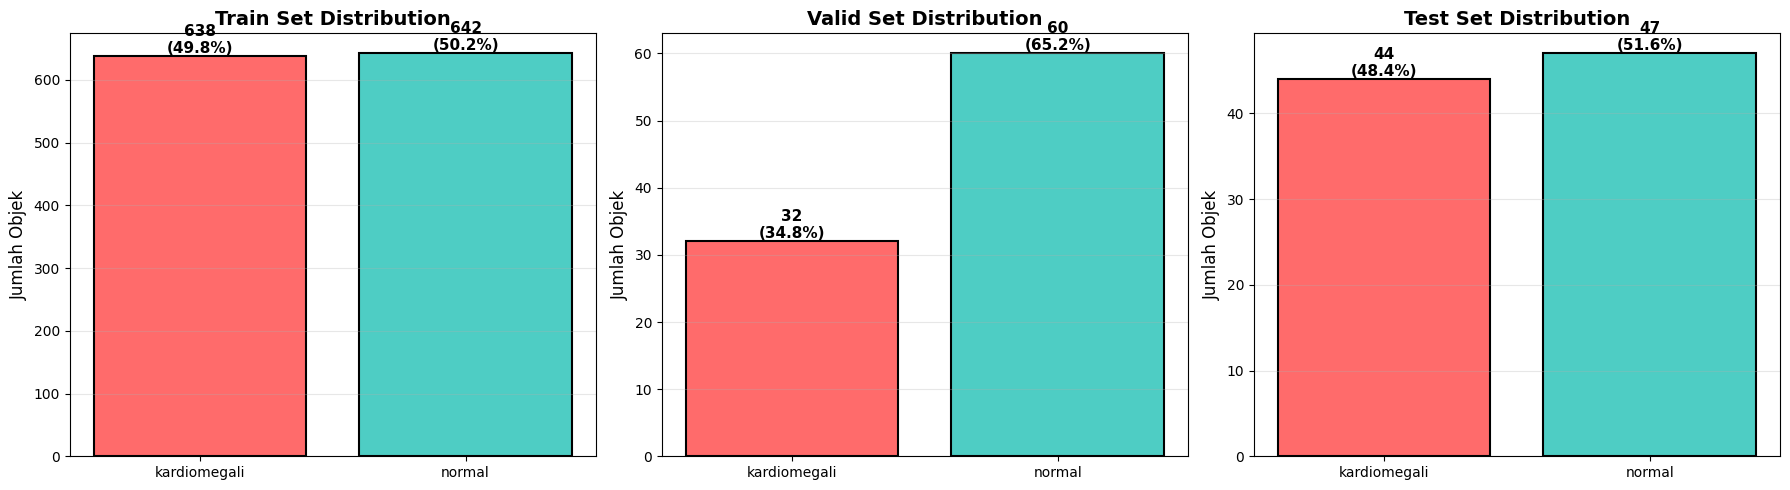

plot saved to: /kaggle/working/outputs/class_distribution.png


In [5]:
def get_split_stats(lbl_dir):
    counts = Counter()
    for lbl_file in Path(lbl_dir).glob('*.txt'):
        with open(lbl_file, 'r') as f:
            for line in f.readlines():
                cls_id = int(line.split()[0])
                counts[cls_id] += 1
    return {'class_counts': dict(counts)}

train_stats = get_split_stats(TRAIN_LBL)
valid_stats = get_split_stats(VALID_LBL)
test_stats  = get_split_stats(TEST_LBL)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
splits = [('Train', train_stats), ('Valid', valid_stats), ('Test', test_stats)]
colors_list = CLASS_COLORS

for idx, (split_name, stats) in enumerate(splits):
    ax = axes[idx]
    counts = [stats['class_counts'].get(0, 0), stats['class_counts'].get(1, 0)]
    bars = ax.bar(CLASS_NAMES, counts, color=colors_list, edgecolor='black', linewidth=1.5)
    total = sum(counts)
    for bar, count in zip(bars, counts):
        height = bar.get_height()
        percentage = (count / total * 100) if total > 0 else 0
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{count}\n({percentage:.1f}%)',
                ha='center', va='bottom', fontweight='bold', fontsize=11)
    ax.set_title(f'{split_name} Set Distribution', fontsize=14, fontweight='bold')
    ax.set_ylabel('Jumlah Objek', fontsize=12)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"plot saved to: {OUTPUT_DIR / 'class_distribution.png'}")


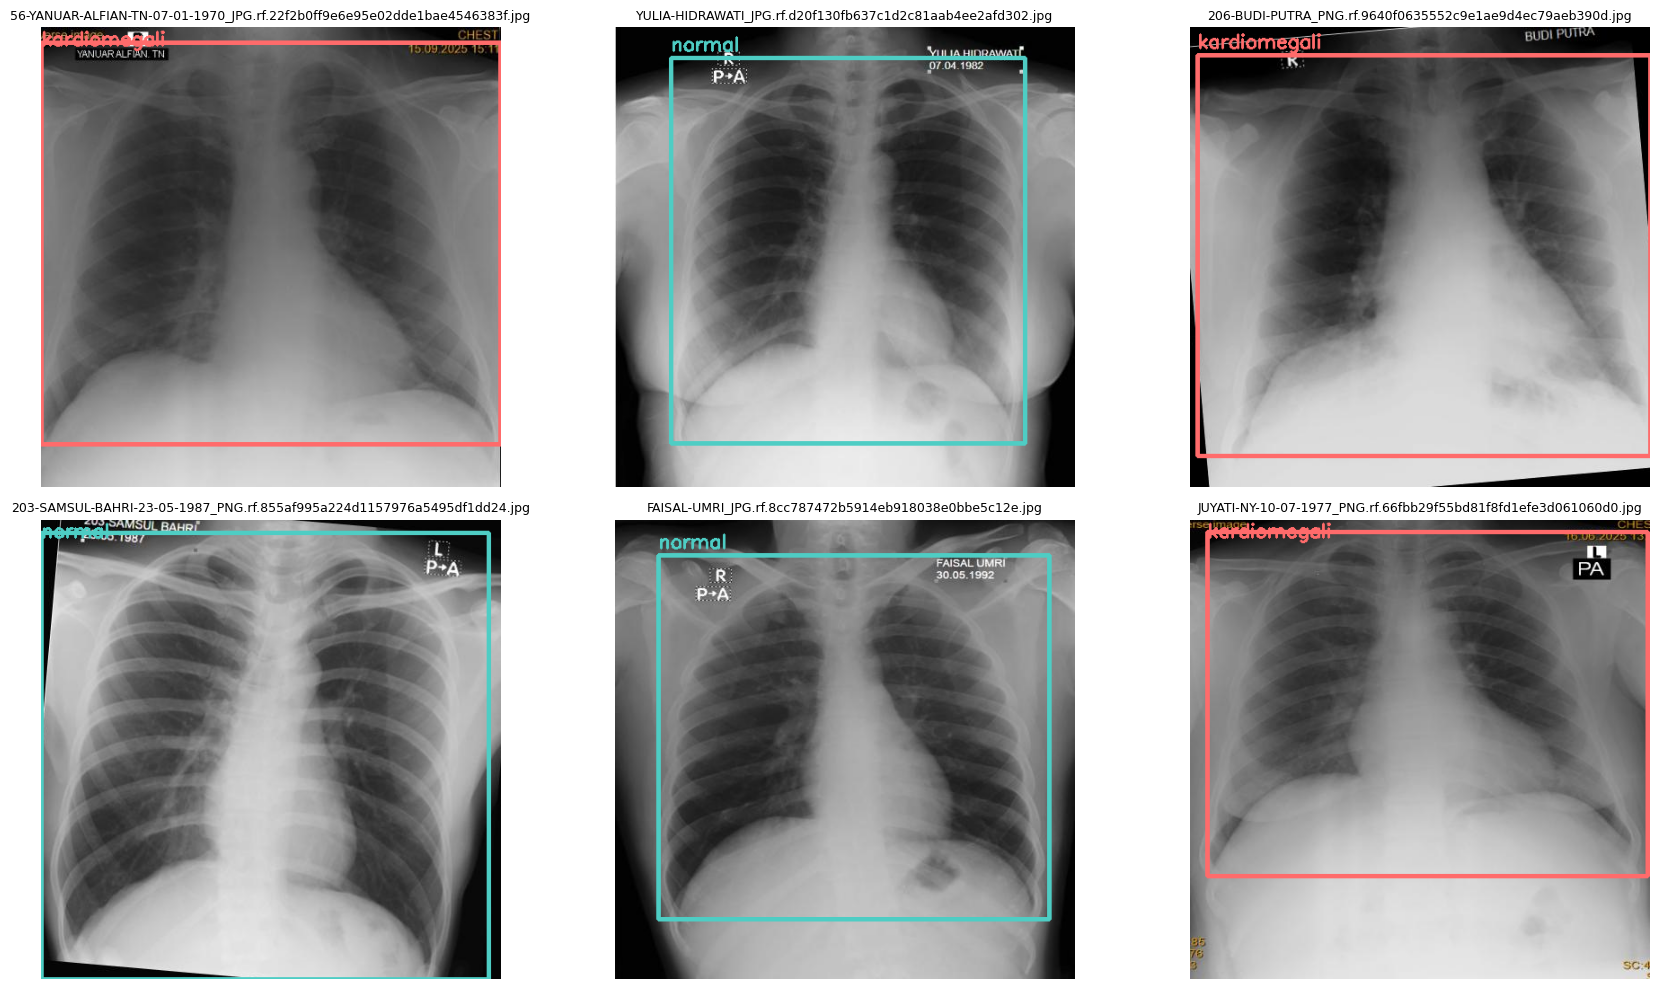

In [9]:
def visualize_samples(split='train', num_samples=6):
    dirs = {'train': (TRAIN_IMG, TRAIN_LBL), 'valid': (VALID_IMG, VALID_LBL), 'test': (TEST_IMG, TEST_LBL)}
    img_dir, lbl_dir = dirs[split]
    image_files = list(img_dir.glob('*.*'))
    if len(image_files) == 0:
        print(f'Tidak ada gambar pada folder: {img_dir}'); return
    random.shuffle(image_files)
    num_samples = min(num_samples, len(image_files))
    rows = 2; cols = (num_samples + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(18, 10))
    axes = [axes] if num_samples == 1 else axes.ravel()

    for idx in range(num_samples):
        img_path = image_files[idx]
        label_path = lbl_dir / f'{img_path.stem}.txt'
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        if label_path.exists():
            for line in label_path.read_text().strip().splitlines():
                data = line.strip().split()
                if len(data) >= 5:
                    class_id = int(data[0])
                    if class_id >= len(CLASS_NAMES):
                        continue
                    cx, cy, bw, bh = map(float, data[1:5])
                    x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
                    x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
                    x1, y1 = max(0, x1), max(0, y1)
                    x2, y2 = min(w, x2), min(h, y2)
                    color = tuple(int(CLASS_COLORS[class_id].lstrip('#')[i:i+2], 16) for i in (0, 2, 4))
                    cv2.rectangle(img, (x1, y1), (x2, y2), color, 3)
                    cv2.putText(img, CLASS_NAMES[class_id], (x1, max(20, y1 - 8)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
        axes[idx].imshow(img); axes[idx].set_title(img_path.name, fontsize=9); axes[idx].axis('off')

    for j in range(num_samples, len(axes)):
        axes[j].axis('off')
    plt.tight_layout(); plt.show()

visualize_samples('train', 6)


## 5. Training YOLOv11s

Hyperparameter training YOLOv11 dicatat pada dict `YOLO_HPARAMS` supaya bisa dipakai kembali di tabel perbandingan hyperparameter (bagian 9).


In [10]:
from ultralytics import YOLO

YOLO_HPARAMS = dict(
    epochs=YOLO_EPOCHS, imgsz=YOLO_SIZE, batch=16, optimizer='SGD',
    lr0=0.01, lrf=0.01, momentum=0.937, weight_decay=0.0005,
    warmup_epochs=3, warmup_momentum=0.8, warmup_bias_lr=0.1,
    patience=7, degrees=3.0, translate=0.05, scale=0.10,
    fliplr=0.0, flipud=0.0, mosaic=0.0, mixup=0.0, copy_paste=0.0,
    erasing=0.0, auto_augment='none',
)

yolo_model = YOLO('yolo11s.pt')

yolo_results = yolo_model.train(
    data=str(DATA_YAML),
    device=0 if torch.cuda.is_available() else 'cpu',
    workers=4,
    project=str(OUTPUT_DIR / 'yolo11'),
    name='thorax',
    exist_ok=True,
    verbose=True,
    plots=True,
    **YOLO_HPARAMS,
)

print('\nYOLOv11 Training done')


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=none, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, format=torch

In [11]:
def find_yolo_best_pt():
    candidates = [
        OUTPUT_DIR / 'yolo11' / 'thorax' / 'weights' / 'best.pt',
    ]
    for c in candidates:
        if c.exists():
            return c
    matches = list(OUTPUT_DIR.rglob('best.pt'))
    if matches:
        return matches[0]
    raise FileNotFoundError('best.pt YOLOv11 tidak ditemukan!')

YOLO_BEST = find_yolo_best_pt()
print(f'Best model: {YOLO_BEST}')


Best model: /kaggle/working/outputs/yolo11/thorax/weights/best.pt


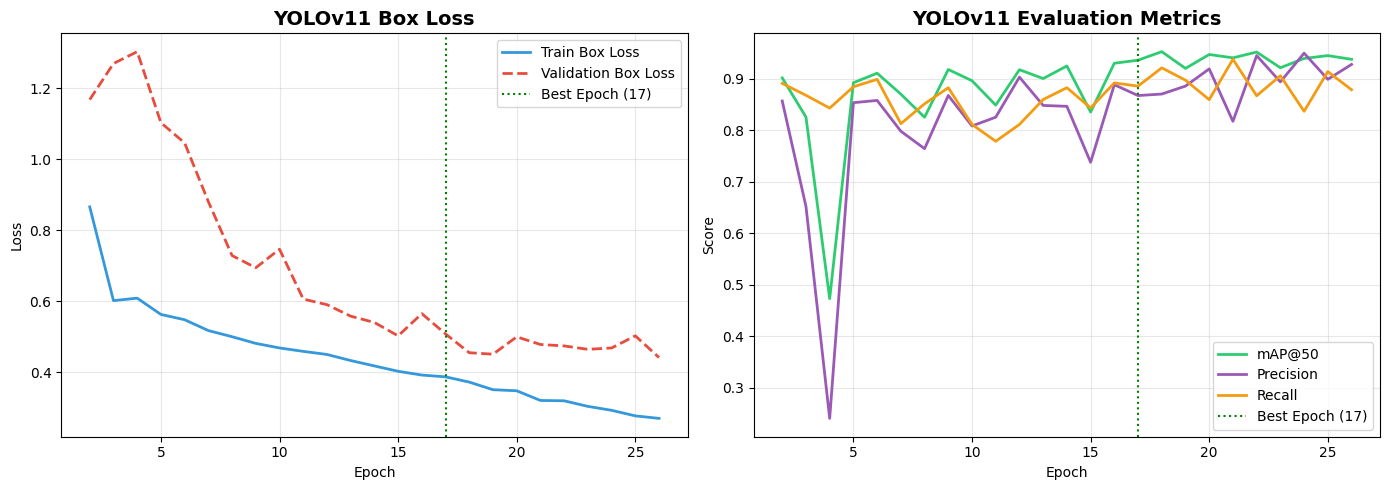

Best Epoch : 17
Best mAP@50: 0.9522


In [12]:
results_csv = YOLO_BEST.parent.parent / 'results.csv'

if results_csv.exists():
    df_yolo = pd.read_csv(results_csv)
    df_yolo.columns = df_yolo.columns.str.strip()

    epochs_r  = df_yolo['epoch'] + 1
    train_loss = df_yolo['train/box_loss']
    val_loss   = df_yolo['val/box_loss']
    map50      = df_yolo['metrics/mAP50(B)']
    precision  = df_yolo['metrics/precision(B)']
    recall     = df_yolo['metrics/recall(B)']
    best_ep    = int(map50.idxmax()) + 1

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(epochs_r, train_loss, label='Train Box Loss', color='#3498DB', linewidth=2)
    ax[0].plot(epochs_r, val_loss, label='Validation Box Loss', color='#E74C3C', linewidth=2, linestyle='--')
    ax[0].axvline(x=best_ep, color='green', linestyle=':', linewidth=1.5, label=f'Best Epoch ({best_ep})')
    ax[0].set_title('YOLOv11 Box Loss', fontsize=14, fontweight='bold')
    ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend(); ax[0].grid(alpha=0.3)

    ax[1].plot(epochs_r, map50, label='mAP@50', color='#2ECC71', linewidth=2)
    ax[1].plot(epochs_r, precision, label='Precision', color='#9B59B6', linewidth=2)
    ax[1].plot(epochs_r, recall, label='Recall', color='#F39C12', linewidth=2)
    ax[1].axvline(x=best_ep, color='green', linestyle=':', linewidth=1.5, label=f'Best Epoch ({best_ep})')
    ax[1].set_title('YOLOv11 Evaluation Metrics', fontsize=14, fontweight='bold')
    ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Score'); ax[1].legend(); ax[1].grid(alpha=0.3)

    plt.tight_layout()
    save_path = OUTPUT_DIR / 'yolov11_training_curves.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Best Epoch : {best_ep}')
    print(f'Best mAP@50: {map50.max():.4f}')
else:
    print('results.csv tidak ditemukan.')


## 6. Training SSD300-VGG16

In [13]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

class ThoraxDatasetSSD(Dataset):
    def __init__(self, img_dir, lbl_dir, img_size=300, augment=False):
        self.img_dir  = Path(img_dir)
        self.lbl_dir  = Path(lbl_dir)
        self.img_size = img_size
        self.augment  = augment
        self.img_files = sorted(
            list(self.img_dir.glob('*.jpg')) +
            list(self.img_dir.glob('*.jpeg')) +
            list(self.img_dir.glob('*.png'))
        )
        self.aug_transform  = self._build_aug()
        self.base_transform = self._build_base()

    def _build_aug(self):
        return A.Compose([
            A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.10, rotate_limit=5,
                                border_mode=cv2.BORDER_CONSTANT, value=0, p=0.6),
            A.RandomBrightnessContrast(brightness_limit=0.20, contrast_limit=0.20, p=0.5),
            A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.4),
            A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
        ], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['class_labels'],
                                     min_visibility=0.3, clip=True))

    def _build_base(self):
        return A.Compose([
            A.Resize(self.img_size, self.img_size),
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2()
        ], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['class_labels'],
                                     min_visibility=0.3, clip=True))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = self.img_files[idx]
        lbl_path = self.lbl_dir / (img_path.stem + '.txt')
        img = np.array(Image.open(img_path).convert('RGB'))
        H, W = img.shape[:2]

        boxes, labels = [], []
        if lbl_path.exists():
            for line in lbl_path.read_text().strip().splitlines():
                p = line.strip().split()
                if len(p) == 5:
                    cls_id = int(p[0])
                    cx, cy, bw, bh = map(float, p[1:])
                    x1 = max(0.0, min((cx - bw/2) * W, W)); y1 = max(0.0, min((cy - bh/2) * H, H))
                    x2 = max(0.0, min((cx + bw/2) * W, W)); y2 = max(0.0, min((cy + bh/2) * H, H))
                    if x2 - x1 >= 2 and y2 - y1 >= 2:
                        boxes.append([x1, y1, x2, y2]); labels.append(cls_id + 1)

        if self.augment and boxes:
            try:
                out = self.aug_transform(image=img, bboxes=boxes, class_labels=labels)
                img, boxes, labels = out['image'], list(out['bboxes']), list(out['class_labels'])
            except Exception:
                pass

        if boxes:
            out = self.base_transform(image=img, bboxes=boxes, class_labels=labels)
            img_t, boxes, labels = out['image'], out['bboxes'], out['class_labels']
        else:
            out = self.base_transform(image=img, bboxes=[], class_labels=[])
            img_t = out['image']

        boxes_t  = torch.tensor(list(boxes), dtype=torch.float32) if boxes else torch.zeros((0, 4), dtype=torch.float32)
        labels_t = torch.tensor(list(labels), dtype=torch.int64) if boxes else torch.zeros((0,), dtype=torch.int64)
        return img_t, {'boxes': boxes_t, 'labels': labels_t}


def collate_fn(batch):
    return tuple(zip(*batch))

train_ds_ssd = ThoraxDatasetSSD(TRAIN_IMG, TRAIN_LBL, SSD_SIZE, augment=True)
valid_ds_ssd = ThoraxDatasetSSD(VALID_IMG, VALID_LBL, SSD_SIZE, augment=False)
test_ds_ssd  = ThoraxDatasetSSD(TEST_IMG,  TEST_LBL,  SSD_SIZE, augment=False)

SSD_BATCH = 8
train_loader_ssd = DataLoader(train_ds_ssd, batch_size=SSD_BATCH, shuffle=True,  collate_fn=collate_fn, num_workers=2, pin_memory=torch.cuda.is_available())
valid_loader_ssd = DataLoader(valid_ds_ssd, batch_size=SSD_BATCH, shuffle=False, collate_fn=collate_fn, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader_ssd  = DataLoader(test_ds_ssd,  batch_size=4,         shuffle=False, collate_fn=collate_fn, num_workers=2, pin_memory=torch.cuda.is_available())

print(f'Dataset SSD — Train: {len(train_ds_ssd)} | Valid: {len(valid_ds_ssd)} | Test: {len(test_ds_ssd)}')


Dataset SSD — Train: 1280 | Valid: 92 | Test: 91


In [14]:
def build_ssd_model(num_classes=NUM_CLASSES, score_thresh=0.01, nms_thresh=0.45):
    model = ssd300_vgg16(weights=SSD300_VGG16_Weights.DEFAULT, score_thresh=score_thresh,
                          nms_thresh=nms_thresh, detections_per_img=10)
    in_channels = [512, 1024, 512, 256, 256, 256]
    num_anchors = model.anchor_generator.num_anchors_per_location()
    model.head.classification_head = SSDClassificationHead(
        in_channels=in_channels, num_anchors=num_anchors, num_classes=num_classes)
    return model

def freeze_backbone(model, freeze_up_to=10):
    for i, (name, param) in enumerate(model.backbone.named_parameters()):
        if i < freeze_up_to:
            param.requires_grad = False

def unfreeze_backbone(model):
    for param in model.backbone.parameters():
        param.requires_grad = True

ssd_model = build_ssd_model().to(DEVICE)
freeze_backbone(ssd_model, freeze_up_to=10)

n_total   = sum(p.numel() for p in ssd_model.parameters())
n_trained = sum(p.numel() for p in ssd_model.parameters() if p.requires_grad)
print(f'SSD Model — Total params: {n_total:,} | Trainable: {n_trained:,}')


Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 216MB/s] 


SSD Model — Total params: 23,879,570 | Trainable: 23,323,986


In [15]:
torch.set_num_threads(4)

SSD_HPARAMS = dict(
    epochs=SSD_EPOCHS, imgsz=SSD_SIZE, batch=SSD_BATCH, optimizer='SGD',
    lr_warmup=5e-4, lr=5e-3, momentum=0.9, weight_decay=5e-4,
    warmup_epochs=3, accum_steps=2, patience=7,
)

SSD_WARMUP_EPOCHS = SSD_HPARAMS['warmup_epochs']
SSD_LR            = SSD_HPARAMS['lr']
SSD_LR_WARMUP     = SSD_HPARAMS['lr_warmup']
SSD_MOMENTUM      = SSD_HPARAMS['momentum']
SSD_WEIGHT_DECAY  = SSD_HPARAMS['weight_decay']
ACCUM_STEPS       = SSD_HPARAMS['accum_steps']
PATIENCE          = SSD_HPARAMS['patience']
SSD_CKPT          = OUTPUT_DIR / 'ssd_best.pt'

optimizer_ssd = optim.SGD(filter(lambda p: p.requires_grad, ssd_model.parameters()),
                           lr=SSD_LR_WARMUP, momentum=SSD_MOMENTUM,
                           weight_decay=SSD_WEIGHT_DECAY, nesterov=True)

def make_main_scheduler(opt, milestones, gamma=0.1):
    return optim.lr_scheduler.MultiStepLR(opt, milestones=milestones, gamma=gamma)

ssd_train_losses, ssd_val_losses = [], []
best_val_loss, no_improve_count = float('inf'), 0

def train_one_epoch_ssd(model, loader, optimizer, device, accum_steps=2):
    model.train(); total_loss = 0.0; optimizer.zero_grad()
    pbar = tqdm(loader, desc='  Train', leave=False)
    for step, (imgs, targets) in enumerate(pbar):
        imgs = [img.to(device) for img in imgs]
        targets = [{'boxes': t['boxes'].to(device), 'labels': t['labels'].to(device)} for t in targets]
        loss_dict = model(imgs, targets)
        loss = sum(loss_dict.values()) / accum_steps
        loss.backward()
        if (step + 1) % accum_steps == 0 or (step + 1) == len(loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step(); optimizer.zero_grad()
        total_loss += loss.item() * accum_steps
        pbar.set_postfix({'loss': f'{loss.item()*accum_steps:.4f}', 'lr': f'{optimizer.param_groups[0]["lr"]:.5f}'})
    return total_loss / len(loader)

@torch.no_grad()
def eval_loss_ssd(model, loader, device):
    model.train(); total_loss = 0.0
    pbar = tqdm(loader, desc='  Valid', leave=False)
    for imgs, targets in pbar:
        imgs = [img.to(device) for img in imgs]
        targets = [{'boxes': t['boxes'].to(device), 'labels': t['labels'].to(device)} for t in targets]
        loss_dict = model(imgs, targets)
        loss = sum(loss_dict.values())
        total_loss += loss.item()
        pbar.set_postfix({'val_loss': f'{loss.item():.4f}'})
    return total_loss / len(loader)

print('Training SSD300 — Best Practice Config')
print(f'  Epochs: {SSD_EPOCHS} | Warmup: {SSD_WARMUP_EPOCHS} | Optimizer: SGD lr={SSD_LR_WARMUP}->{SSD_LR}')
print(f'  Accum steps: {ACCUM_STEPS} (effective batch={SSD_BATCH*ACCUM_STEPS}) | Patience: {PATIENCE}')

main_scheduler = None
for epoch in range(1, SSD_EPOCHS + 1):
    print(f'\nEpoch {epoch}/{SSD_EPOCHS}')
    if epoch == SSD_WARMUP_EPOCHS + 1:
        print('  [Unfreeze] Backbone penuh di-unfreeze, LR dinaikkan')
        unfreeze_backbone(ssd_model)
        optimizer_ssd = optim.SGD(ssd_model.parameters(), lr=SSD_LR, momentum=SSD_MOMENTUM,
                                   weight_decay=SSD_WEIGHT_DECAY, nesterov=True)
        remaining = SSD_EPOCHS - SSD_WARMUP_EPOCHS
        m1 = SSD_WARMUP_EPOCHS + int(remaining * 0.5)
        m2 = SSD_WARMUP_EPOCHS + int(remaining * 0.8)
        main_scheduler = make_main_scheduler(optimizer_ssd, milestones=[m1, m2])
        print(f'  Scheduler milestones: epoch {m1} dan {m2}')

    train_loss = train_one_epoch_ssd(ssd_model, train_loader_ssd, optimizer_ssd, DEVICE, ACCUM_STEPS)
    val_loss   = eval_loss_ssd(ssd_model, valid_loader_ssd, DEVICE)
    if main_scheduler is not None:
        main_scheduler.step()

    ssd_train_losses.append(train_loss); ssd_val_losses.append(val_loss)

    save_flag = ''
    if val_loss < best_val_loss:
        best_val_loss = val_loss; no_improve_count = 0
        torch.save(ssd_model.state_dict(), SSD_CKPT)
        save_flag = 'Best Saved'
    else:
        no_improve_count += 1

    cur_lr = optimizer_ssd.param_groups[0]['lr']
    print(f'  Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | LR: {cur_lr:.6f} | No-improve: {no_improve_count}/{PATIENCE} {save_flag}')

    if no_improve_count >= PATIENCE and epoch > SSD_WARMUP_EPOCHS + 5:
        print(f'\n  Early stopping triggered di epoch {epoch}.')
        break

print(f'\nSSD Training selesai — Best Val Loss: {best_val_loss:.4f}')
print(f'  Model tersimpan di: {SSD_CKPT}')


Training SSD300 — Best Practice Config
  Epochs: 25 | Warmup: 3 | Optimizer: SGD lr=0.0005->0.005
  Accum steps: 2 (effective batch=16) | Patience: 7

Epoch 1/25


  Train Loss: 6.5772 | Val Loss: 3.3503 | LR: 0.000500 | No-improve: 0/7 Best Saved

Epoch 2/25


  Train Loss: 2.8734 | Val Loss: 2.2816 | LR: 0.000500 | No-improve: 0/7 Best Saved

Epoch 3/25


  Train Loss: 2.2599 | Val Loss: 1.8143 | LR: 0.000500 | No-improve: 0/7 Best Saved

Epoch 4/25
  [Unfreeze] Backbone penuh di-unfreeze, LR dinaikkan
  Scheduler milestones: epoch 14 dan 20


  Train Loss: 1.9584 | Val Loss: 1.2787 | LR: 0.005000 | No-improve: 0/7 Best Saved

Epoch 5/25


  Train Loss: 1.3667 | Val Loss: 1.2080 | LR: 0.005000 | No-improve: 0/7 Best Saved

Epoch 6/25


... (16 outputs left out)

  Train Loss: 0.3171 | Val Loss: 0.8153 | LR: 0.000500 | No-improve: 2/7 

Epoch 23/25


  Train Loss: 0.3191 | Val Loss: 0.8798 | LR: 0.000050 | No-improve: 3/7 

Epoch 24/25


  Train Loss: 0.2710 | Val Loss: 0.8546 | LR: 0.000050 | No-improve: 4/7 

Epoch 25/25


  Train Loss: 0.3000 | Val Loss: 0.8418 | LR: 0.000050 | No-improve: 5/7 

SSD Training selesai — Best Val Loss: 0.7813
  Model tersimpan di: /kaggle/working/outputs/ssd_best.pt


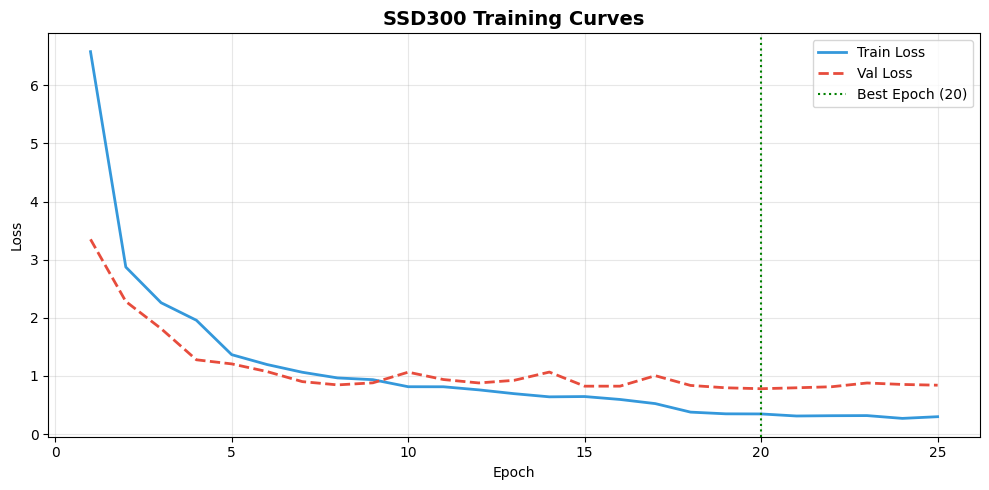

disimpan: outputs/ssd_training_curves.png


In [16]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
epochs_r = range(1, len(ssd_train_losses) + 1)
ax.plot(epochs_r, ssd_train_losses, label='Train Loss', color='#3498DB', linewidth=2)
ax.plot(epochs_r, ssd_val_losses,   label='Val Loss',   color='#E74C3C', linewidth=2, linestyle='--')
best_ep = int(np.argmin(ssd_val_losses)) + 1
ax.axvline(x=best_ep, color='green', linestyle=':', linewidth=1.5, label=f'Best Epoch ({best_ep})')
ax.set_title('SSD300 Training Curves', fontsize=14, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ssd_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('disimpan: outputs/ssd_training_curves.png')


## 7. Evaluasi mAP (Test Set) — YOLOv11 & SSD300

In [17]:
from ultralytics import YOLO as YOLO_eval

yolo_eval_model = YOLO_eval(str(YOLO_BEST))
print('Evaluasi YOLOv11 pada Test Set...')
t0 = time.perf_counter()
yolo_metrics = yolo_eval_model.val(data=str(DATA_YAML), split='test',
                                    device=0 if torch.cuda.is_available() else 'cpu', verbose=True)
yolo_infer_time = (time.perf_counter() - t0) / len(test_data) * 1000  # ms/img

yolo_map50     = float(yolo_metrics.box.map50)
yolo_map50_95  = float(yolo_metrics.box.map)
yolo_precision = float(yolo_metrics.box.mp)
yolo_recall    = float(yolo_metrics.box.mr)
yolo_f1        = 2 * yolo_precision * yolo_recall / (yolo_precision + yolo_recall + 1e-8)

yolo_per_class = {}
for i, cls_name in enumerate(CLASS_NAMES):
    yolo_per_class[cls_name] = {
        'precision': float(yolo_metrics.box.p[i]) if len(yolo_metrics.box.p) > i else 0.0,
        'recall':    float(yolo_metrics.box.r[i]) if len(yolo_metrics.box.r) > i else 0.0,
        'mAP50':     float(yolo_metrics.box.ap50[i]) if len(yolo_metrics.box.ap50) > i else 0.0,
    }

print('\nYOLOv11 Test Metrics:')
print(f'  mAP@50: {yolo_map50:.4f} | mAP@50-95: {yolo_map50_95:.4f}')
print(f'  Precision: {yolo_precision:.4f} | Recall: {yolo_recall:.4f} | F1: {yolo_f1:.4f}')
print(f'  Inf Time: ~{yolo_infer_time:.1f} ms/gambar')
for k, v in yolo_per_class.items():
    print(f'    {k:15s}: P={v["precision"]:.4f} | R={v["recall"]:.4f} | mAP50={v["mAP50"]:.4f}')


Evaluasi YOLOv11 pada Test Set...
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 38.7±5.9 MB/s, size: 19.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/test/labels... 91 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 91/91 1.2Kit/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.9it/s 1.5s0.3s
                   all         91         91      0.718      0.842      0.807      0.721
          kardiomegali     

In [18]:
try:
    from torchmetrics.detection.mean_ap import MeanAveragePrecision
except ImportError:
    import subprocess; subprocess.run(['pip', 'install', 'torchmetrics', '-q'])
    from torchmetrics.detection.mean_ap import MeanAveragePrecision

ssd_model.load_state_dict(torch.load(SSD_CKPT, map_location=DEVICE, weights_only=True))
ssd_model.eval().to(DEVICE)

CONF_THRESH = 0.5
IOU_THRESH  = 0.5

metric_map = MeanAveragePrecision(iou_type='bbox', class_metrics=True)
all_preds_pr, all_targets_pr = [], []

print('Evaluasi SSD pada Test Set...')
t0 = time.perf_counter()
with torch.no_grad():
    for imgs, targets in tqdm(test_loader_ssd, desc='SSD Eval'):
        imgs = [img.to(DEVICE) for img in imgs]
        preds = ssd_model(imgs)
        for pred, tgt in zip(preds, targets):
            keep = pred['scores'] >= CONF_THRESH
            all_preds_pr.append({'boxes': pred['boxes'][keep].cpu(), 'scores': pred['scores'][keep].cpu(), 'labels': pred['labels'][keep].cpu()})
            all_targets_pr.append({'boxes': tgt['boxes'].cpu(), 'labels': tgt['labels'].cpu()})
        preds_cpu   = [{'boxes': p['boxes'].cpu(), 'scores': p['scores'].cpu(), 'labels': p['labels'].cpu()} for p in preds]
        targets_cpu = [{'boxes': t['boxes'].cpu(), 'labels': t['labels'].cpu()} for t in targets]
        metric_map.update(preds_cpu, targets_cpu)

ssd_infer_time = (time.perf_counter() - t0) / len(test_ds_ssd) * 1000
ssd_map_results = metric_map.compute()
ssd_map50    = float(ssd_map_results['map_50'])
ssd_map50_95 = float(ssd_map_results['map'])

def compute_pr_per_class(all_preds, all_targets, num_fg_classes, iou_threshold=0.5):
    stats = {c: {'TP': 0, 'FP': 0, 'FN': 0} for c in range(1, num_fg_classes + 1)}
    for pred, tgt in zip(all_preds, all_targets):
        pred_boxes, pred_labels = pred['boxes'], pred['labels']
        gt_boxes, gt_labels = tgt['boxes'], tgt['labels']
        matched_gt = set()
        for i in range(len(pred_boxes)):
            pb, pl = pred_boxes[i], int(pred_labels[i])
            best_iou, best_j = 0.0, -1
            for j in range(len(gt_boxes)):
                if j in matched_gt or int(gt_labels[j]) != pl:
                    continue
                iou = box_iou_xyxy(pb.tolist(), gt_boxes[j].tolist())
                if iou > best_iou:
                    best_iou, best_j = iou, j
            if best_iou >= iou_threshold:
                stats[pl]['TP'] += 1; matched_gt.add(best_j)
            else:
                if pl in stats:
                    stats[pl]['FP'] += 1
        for j in range(len(gt_boxes)):
            gl = int(gt_labels[j])
            if j not in matched_gt and gl in stats:
                stats[gl]['FN'] += 1
    precision, recall = {}, {}
    for c, s in stats.items():
        precision[c] = s['TP'] / (s['TP'] + s['FP'] + 1e-8)
        recall[c]    = s['TP'] / (s['TP'] + s['FN'] + 1e-8)
    return precision, recall

def box_iou_xyxy(boxA, boxB):
    xA, yA = max(boxA[0], boxB[0]), max(boxA[1], boxB[1])
    xB, yB = min(boxA[2], boxB[2]), min(boxA[3], boxB[3])
    inter = max(0, xB - xA) * max(0, yB - yA)
    areaA = (boxA[2]-boxA[0]) * (boxA[3]-boxA[1])
    areaB = (boxB[2]-boxB[0]) * (boxB[3]-boxB[1])
    return inter / (areaA + areaB - inter + 1e-8)

ssd_precision_cls, ssd_recall_cls = compute_pr_per_class(all_preds_pr, all_targets_pr, num_fg_classes=2, iou_threshold=IOU_THRESH)
ssd_precision = np.mean(list(ssd_precision_cls.values()))
ssd_recall    = np.mean(list(ssd_recall_cls.values()))
ssd_f1        = 2 * ssd_precision * ssd_recall / (ssd_precision + ssd_recall + 1e-8)

ssd_per_class = {}
if 'map_per_class' in ssd_map_results:
    for i, cls_name in enumerate(CLASS_NAMES):
        ssd_per_class[cls_name] = {
            'precision': ssd_precision_cls.get(i+1, 0.0), 'recall': ssd_recall_cls.get(i+1, 0.0),
            'mAP50': float(ssd_map_results['map_per_class'][i]) if i < len(ssd_map_results['map_per_class']) else 0.0,
        }

print('\nSSD Test Metrics:')
print(f'  mAP@50: {ssd_map50:.4f} | mAP@50-95: {ssd_map50_95:.4f}')
print(f'  Precision: {ssd_precision:.4f} | Recall: {ssd_recall:.4f} | F1: {ssd_f1:.4f}')
print(f'  Inf Time: ~{ssd_infer_time:.1f} ms/gambar')
for k, v in ssd_per_class.items():
    print(f'    {k:15s}: P={v["precision"]:.4f} | R={v["recall"]:.4f} | mAP50={v["mAP50"]:.4f}')


Evaluasi SSD pada Test Set...


SSD Eval: 100%|██████████| 23/23 [00:01<00:00, 11.58it/s]



SSD Test Metrics:
  mAP@50: 0.8603 | mAP@50-95: 0.7306
  Precision: 0.8007 | Recall: 0.7984 | F1: 0.7995
  Inf Time: ~21.9 ms/gambar
    kardiomegali   : P=0.6667 | R=0.6818 | mAP50=0.6017
    normal         : P=0.9348 | R=0.9149 | mAP50=0.8594


## 8. Confusion Matrix — Validasi & Uji (Revisi Sidang #1)

Fungsi `evaluate_yolo_confusion_matrix()` dan `evaluate_ssd_confusion_matrix()` dibuat generik menerima parameter `split` (`'valid'` atau `'test'`), sehingga confusion matrix bisa dihasilkan untuk **kedua split** seperti diminta penguji.


######################################################################
CONFUSION MATRIX YOLO11 — VALID SET
######################################################################
Running YOLOv11 predictions on valid set...


100%|██████████| 92/92 [00:01<00:00, 63.02it/s]


Detailed results saved to: /kaggle/working/outputs/yolo11_valid_results.csv
No Detection: 2 gambar dari 92
Accuracy Model YOLO11 (valid): 96.67%


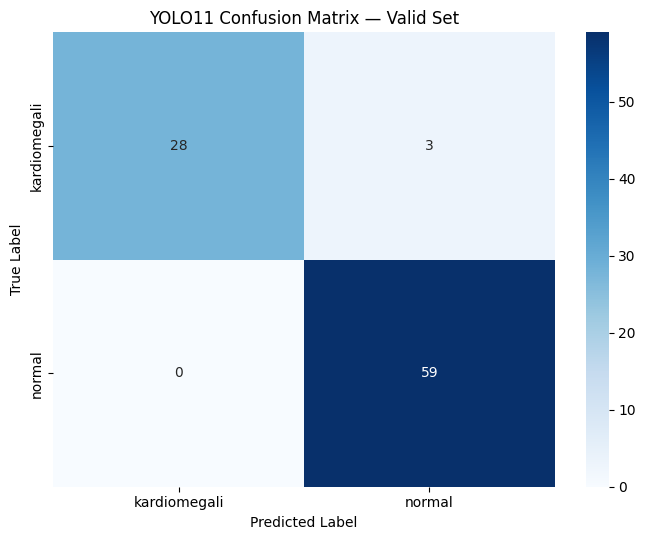

Confusion matrix saved to: /kaggle/working/outputs/yolo11_confusion_matrix_valid.png

YOLO11 CLASSIFICATION REPORT — VALID SET
              precision    recall  f1-score   support

kardiomegali     1.0000    0.8750    0.9333        32
      normal     0.9516    0.9833    0.9672        60

   micro avg     0.9667    0.9457    0.9560        92
   macro avg     0.9758    0.9292    0.9503        92
weighted avg     0.9684    0.9457    0.9554        92


######################################################################
CONFUSION MATRIX YOLO11 — TEST SET
######################################################################
Running YOLOv11 predictions on test set...


100%|██████████| 91/91 [00:01<00:00, 73.75it/s]


Detailed results saved to: /kaggle/working/outputs/yolo11_test_results.csv
No Detection: 0 gambar dari 91
Accuracy Model YOLO11 (test): 91.21%


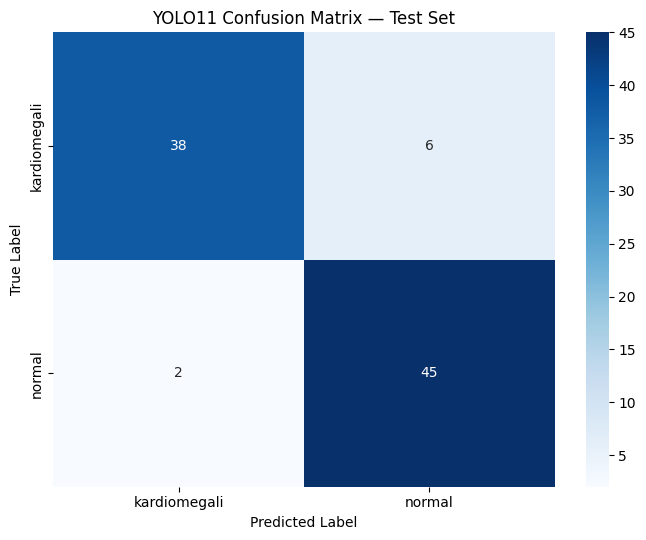

Confusion matrix saved to: /kaggle/working/outputs/yolo11_confusion_matrix_test.png

YOLO11 CLASSIFICATION REPORT — TEST SET
              precision    recall  f1-score   support

kardiomegali     0.9500    0.8636    0.9048        44
      normal     0.8824    0.9574    0.9184        47

    accuracy                         0.9121        91
   macro avg     0.9162    0.9105    0.9116        91
weighted avg     0.9151    0.9121    0.9118        91



In [19]:
def evaluate_yolo_confusion_matrix(split='test'):
    img_dir, lbl_dir = (VALID_IMG, VALID_LBL) if split == 'valid' else (TEST_IMG, TEST_LBL)
    image_files = sorted(list(img_dir.glob('*')))

    y_true, y_pred, y_scores, detailed_results = [], [], [], []
    print(f"Running YOLOv11 predictions on {split} set...")
    for img_path in tqdm(image_files):
        label_path = lbl_dir / f'{img_path.stem}.txt'
        if not label_path.exists():
            continue
        gt_lines = label_path.read_text().strip().splitlines()
        if len(gt_lines) == 0:
            continue
        gt_class = int(gt_lines[0].split()[0])
        y_true.append(gt_class)

        results = model_yolo11.predict(source=str(img_path), conf=0.5, iou=0.5, device=DEVICE, verbose=False)
        if len(results[0].boxes) > 0:
            confidences = results[0].boxes.conf.cpu().numpy()
            classes     = results[0].boxes.cls.cpu().numpy().astype(int)
            best_idx    = confidences.argmax()
            pred_class, pred_conf = int(classes[best_idx]), float(confidences[best_idx])
            y_pred.append(pred_class); y_scores.append(pred_conf)
        else:
            y_pred.append(-1); y_scores.append(0.0)

        pred_idx = y_pred[-1]
        detailed_results.append({
            'image': img_path.name, 'true_class': CLASS_NAMES[gt_class],
            'pred_class': CLASS_NAMES[pred_idx] if pred_idx != -1 else 'No Detection',
            'confidence': y_scores[-1], 'correct': gt_class == pred_idx,
        })

    df_results = pd.DataFrame(detailed_results)
    csv_path = OUTPUT_DIR / f'yolo11_{split}_results.csv'
    df_results.to_csv(csv_path, index=False)
    print(f'Detailed results saved to: {csv_path}')

    no_det = y_pred.count(-1)
    print(f'No Detection: {no_det} gambar dari {len(y_true)}')

    detected_mask = [p != -1 for p in y_pred]
    y_true_det = [y_true[i] for i in range(len(detected_mask)) if detected_mask[i]]
    y_pred_det = [y_pred[i] for i in range(len(detected_mask)) if detected_mask[i]]
    accuracy_det = accuracy_score(y_true_det, y_pred_det) if y_true_det else 0.0
    print(f'Accuracy Model YOLO11 ({split}): {accuracy_det*100:.2f}%')

    cm = confusion_matrix(y_true_det, y_pred_det, labels=list(range(len(CLASS_NAMES))))
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'YOLO11 Confusion Matrix — {split.capitalize()} Set')
    plt.xlabel('Predicted Label'); plt.ylabel('True Label')
    plt.tight_layout()
    cm_path = OUTPUT_DIR / f'yolo11_confusion_matrix_{split}.png'
    plt.savefig(cm_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Confusion matrix saved to: {cm_path}')

    print('\n' + '='*60)
    print(f'YOLO11 CLASSIFICATION REPORT — {split.upper()} SET')
    print('='*60)
    print(classification_report(y_true, y_pred, labels=list(range(len(CLASS_NAMES))),
                                 target_names=CLASS_NAMES, digits=4, zero_division=0))
    print('='*60)
    return cm, df_results

from ultralytics import YOLO
model_yolo11 = YOLO(str(YOLO_BEST))

print('#'*70); print('CONFUSION MATRIX YOLO11 — VALID SET'); print('#'*70)
yolo_cm_valid, yolo_valid_results = evaluate_yolo_confusion_matrix(split='valid')

print('\n' + '#'*70); print('CONFUSION MATRIX YOLO11 — TEST SET'); print('#'*70)
yolo_cm_test, yolo_test_results = evaluate_yolo_confusion_matrix(split='test')


######################################################################
CONFUSION MATRIX SSD300 — VALID SET
######################################################################
Running SSD predictions on valid set...


100%|██████████| 12/12 [00:01<00:00,  6.04it/s]


Detailed results saved to: /kaggle/working/outputs/ssd_valid_results.csv
No Detection: 0 gambar dari 92
Accuracy Model SSD (valid): 96.74%


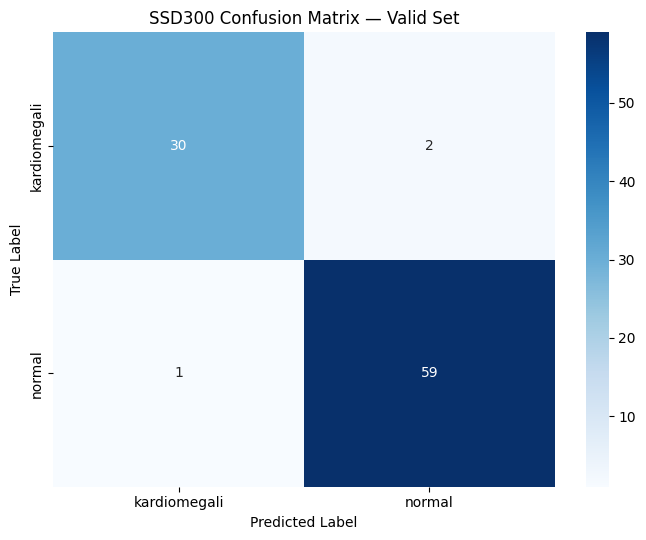

Confusion matrix saved to: /kaggle/working/outputs/ssd_confusion_matrix_valid.png

SSD300 CLASSIFICATION REPORT — VALID SET
              precision    recall  f1-score   support

kardiomegali     0.9677    0.9375    0.9524        32
      normal     0.9672    0.9833    0.9752        60

    accuracy                         0.9674        92
   macro avg     0.9675    0.9604    0.9638        92
weighted avg     0.9674    0.9674    0.9673        92


######################################################################
CONFUSION MATRIX SSD300 — TEST SET
######################################################################
Running SSD predictions on test set...


100%|██████████| 23/23 [00:01<00:00, 11.70it/s]


Detailed results saved to: /kaggle/working/outputs/ssd_test_results.csv
No Detection: 2 gambar dari 91
Accuracy Model SSD (test): 92.13%


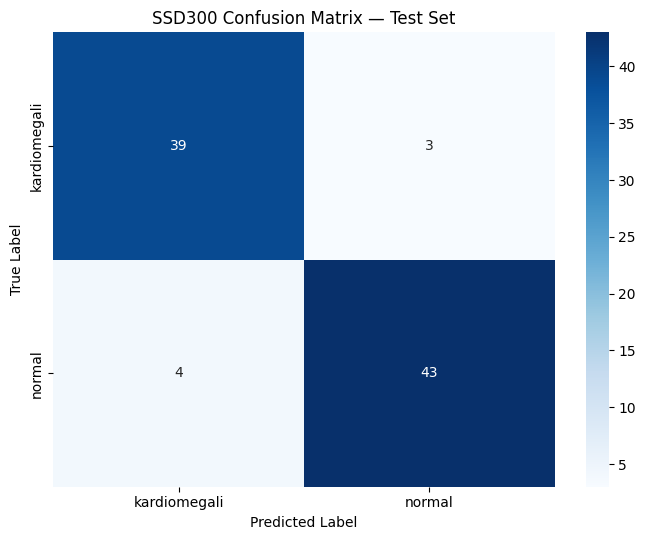

Confusion matrix saved to: /kaggle/working/outputs/ssd_confusion_matrix_test.png

SSD300 CLASSIFICATION REPORT — TEST SET
              precision    recall  f1-score   support

kardiomegali     0.9070    0.8864    0.8966        44
      normal     0.9348    0.9149    0.9247        47

   micro avg     0.9213    0.9011    0.9111        91
   macro avg     0.9209    0.9006    0.9106        91
weighted avg     0.9213    0.9011    0.9111        91



In [20]:
def evaluate_ssd_confusion_matrix(split='test'):
    loader = valid_loader_ssd if split == 'valid' else test_loader_ssd
    y_true, y_pred, y_scores, detailed_results = [], [], [], []
    print(f"Running SSD predictions on {split} set...")
    with torch.no_grad():
        for imgs, targets in tqdm(loader):
            imgs = [img.to(DEVICE) for img in imgs]
            predictions = ssd_model(imgs)
            for pred, target in zip(predictions, targets):
                if len(target['labels']) == 0:
                    continue
                gt_class = int(target['labels'][0].item()) - 1
                y_true.append(gt_class)

                keep = pred['scores'] >= 0.5
                boxes, scores, labels = pred['boxes'][keep], pred['scores'][keep], pred['labels'][keep]
                if len(scores) > 0:
                    best_idx = scores.argmax()
                    pred_class, pred_conf = int(labels[best_idx].item()) - 1, float(scores[best_idx].item())
                    y_pred.append(pred_class); y_scores.append(pred_conf)
                else:
                    y_pred.append(-1); y_scores.append(0.0)

                pred_idx = y_pred[-1]
                detailed_results.append({
                    'true_class': CLASS_NAMES[y_true[-1]],
                    'pred_class': CLASS_NAMES[pred_idx] if pred_idx != -1 else 'No Detection',
                    'confidence': y_scores[-1], 'correct': y_true[-1] == pred_idx,
                })

    df_results = pd.DataFrame(detailed_results)
    csv_path = OUTPUT_DIR / f'ssd_{split}_results.csv'
    df_results.to_csv(csv_path, index=False)
    print(f'Detailed results saved to: {csv_path}')

    no_det = y_pred.count(-1)
    print(f'No Detection: {no_det} gambar dari {len(y_true)}')

    detected_mask = [p != -1 for p in y_pred]
    y_true_det = [y_true[i] for i in range(len(detected_mask)) if detected_mask[i]]
    y_pred_det = [y_pred[i] for i in range(len(detected_mask)) if detected_mask[i]]
    accuracy_det = accuracy_score(y_true_det, y_pred_det) if y_true_det else 0.0
    print(f'Accuracy Model SSD ({split}): {accuracy_det*100:.2f}%')

    cm = confusion_matrix(y_true_det, y_pred_det, labels=list(range(len(CLASS_NAMES))))
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'SSD300 Confusion Matrix — {split.capitalize()} Set')
    plt.xlabel('Predicted Label'); plt.ylabel('True Label')
    plt.tight_layout()
    cm_path = OUTPUT_DIR / f'ssd_confusion_matrix_{split}.png'
    plt.savefig(cm_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Confusion matrix saved to: {cm_path}')

    print('\n' + '='*60)
    print(f'SSD300 CLASSIFICATION REPORT — {split.upper()} SET')
    print('='*60)
    print(classification_report(y_true, y_pred, labels=list(range(len(CLASS_NAMES))),
                                 target_names=CLASS_NAMES, digits=4, zero_division=0))
    print('='*60)
    return cm, df_results

ssd_model.load_state_dict(torch.load(SSD_CKPT, map_location=DEVICE, weights_only=True))
ssd_model.eval().to(DEVICE)

print('#'*70); print('CONFUSION MATRIX SSD300 — VALID SET'); print('#'*70)
ssd_cm_valid, ssd_valid_results = evaluate_ssd_confusion_matrix(split='valid')

print('\n' + '#'*70); print('CONFUSION MATRIX SSD300 — TEST SET'); print('#'*70)
ssd_cm_test, ssd_test_results = evaluate_ssd_confusion_matrix(split='test')


## 9. Tabel Perbandingan Hyperparameter (Revisi Sidang #2)

Membandingkan hyperparameter training yang dipakai masing-masing algoritma secara berdampingan.


TABEL PERBANDINGAN HYPERPARAMETER
----------------------------------------------------------------------
            Hyperparameter                               YOLO11s                                      SSD300-VGG16
     Backbone / Arsitektur                               YOLO11s                                      SSD300-VGG16
         Ukuran input (px)                                   512                                               300
             Epochs (maks)                                    25                                                25
                Batch size                                    16                                                 8
                 Optimizer                                   SGD                                               SGD
        Learning rate awal                                  0.01                                            0.0005
 Learning rate akhir/utama                                  0.01                          

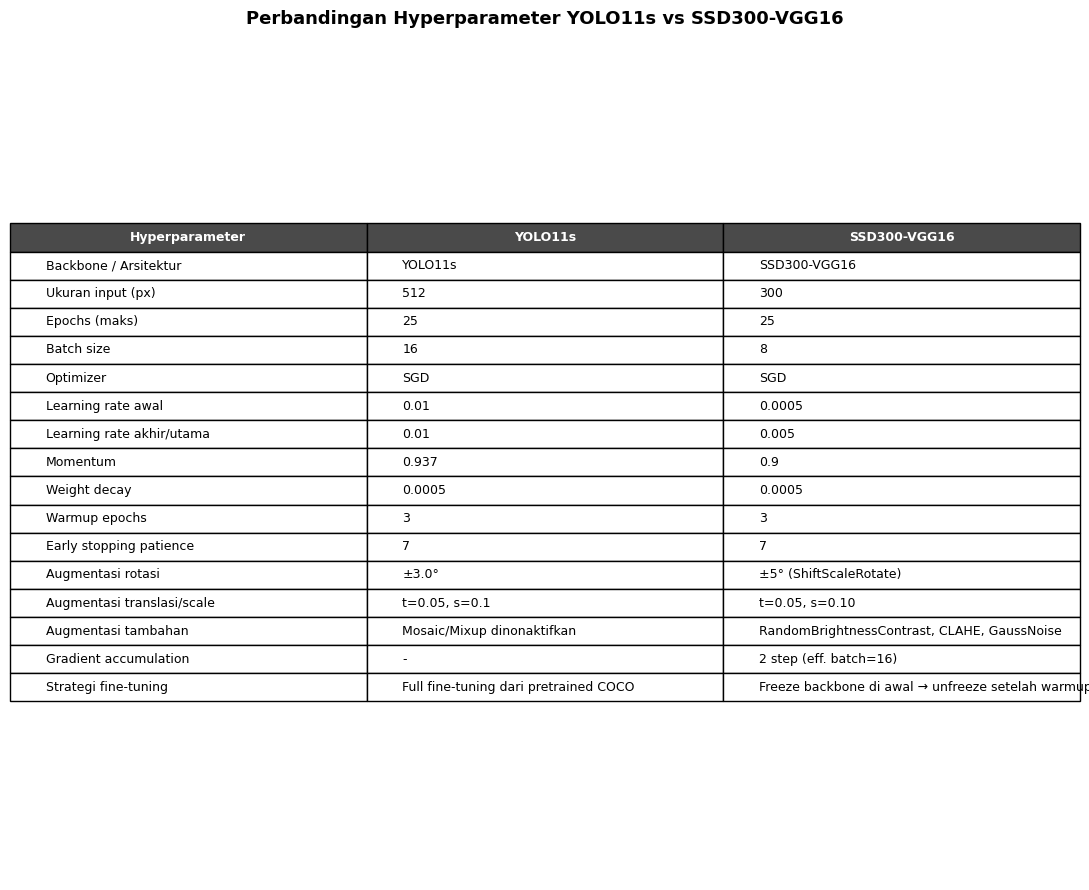

Table image saved: /kaggle/working/outputs/hyperparameter_comparison.png


In [21]:
hparam_rows = [
    ('Backbone / Arsitektur', 'YOLO11s', 'SSD300-VGG16'),
    ('Ukuran input (px)',      YOLO_HPARAMS['imgsz'],   SSD_HPARAMS['imgsz']),
    ('Epochs (maks)',          YOLO_HPARAMS['epochs'],  SSD_HPARAMS['epochs']),
    ('Batch size',             YOLO_HPARAMS['batch'],   SSD_HPARAMS['batch']),
    ('Optimizer',              YOLO_HPARAMS['optimizer'], SSD_HPARAMS['optimizer']),
    ('Learning rate awal',     YOLO_HPARAMS['lr0'],     SSD_HPARAMS['lr_warmup']),
    ('Learning rate akhir/utama', YOLO_HPARAMS['lrf'],  SSD_HPARAMS['lr']),
    ('Momentum',                YOLO_HPARAMS['momentum'], SSD_HPARAMS['momentum']),
    ('Weight decay',            YOLO_HPARAMS['weight_decay'], SSD_HPARAMS['weight_decay']),
    ('Warmup epochs',           YOLO_HPARAMS['warmup_epochs'], SSD_HPARAMS['warmup_epochs']),
    ('Early stopping patience', YOLO_HPARAMS['patience'], SSD_HPARAMS['patience']),
    ('Augmentasi rotasi',       f"±{YOLO_HPARAMS['degrees']}°", '±5° (ShiftScaleRotate)'),
    ('Augmentasi translasi/scale', f"t={YOLO_HPARAMS['translate']}, s={YOLO_HPARAMS['scale']}", 't=0.05, s=0.10'),
    ('Augmentasi tambahan',     'Mosaic/Mixup dinonaktifkan', 'RandomBrightnessContrast, CLAHE, GaussNoise'),
    ('Gradient accumulation',   '-', f"{SSD_HPARAMS['accum_steps']} step (eff. batch={SSD_HPARAMS['batch']*SSD_HPARAMS['accum_steps']})"),
    ('Strategi fine-tuning',    'Full fine-tuning dari pretrained COCO', 'Freeze backbone di awal → unfreeze setelah warmup'),
]

hparam_df = pd.DataFrame(hparam_rows, columns=['Hyperparameter', 'YOLO11s', 'SSD300-VGG16'])
print('TABEL PERBANDINGAN HYPERPARAMETER')
print('-'*70)
print(hparam_df.to_string(index=False))

hparam_csv = OUTPUT_DIR / 'hyperparameter_comparison.csv'
hparam_df.to_csv(hparam_csv, index=False)
print(f'\nCSV saved: {hparam_csv}')

# render sebagai tabel gambar (siap ditempel ke laporan/skripsi)
fig, ax = plt.subplots(figsize=(11, 0.5 * len(hparam_df) + 1))
ax.axis('off')
tbl = ax.table(cellText=hparam_df.values, colLabels=hparam_df.columns, loc='center', cellLoc='left')
tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.4)
for j in range(len(hparam_df.columns)):
    tbl[0, j].set_facecolor('#4A4A4A'); tbl[0, j].set_text_props(color='white', fontweight='bold')
plt.title('Perbandingan Hyperparameter YOLO11s vs SSD300-VGG16', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
hparam_png = OUTPUT_DIR / 'hyperparameter_comparison.png'
plt.savefig(hparam_png, dpi=200, bbox_inches='tight')
plt.show()
print(f'Table image saved: {hparam_png}')


## 10. Tabel & Grafik Perbandingan Akhir Metrik Model


----------------------------------------------------------------------
TABEL PERBANDINGAN AKHIR
----------------------------------------------------------------------
       Model  mAP@50  mAP@50-95  Precision  Recall  F1 Score  Inf (ms)
     YOLO11s  0.8071     0.7210     0.7183  0.8424    0.7754     52.61
SSD300-VGG16  0.8603     0.7306     0.8007  0.7984    0.7995     21.88

CSV saved: /kaggle/working/outputs/comparison_results.csv


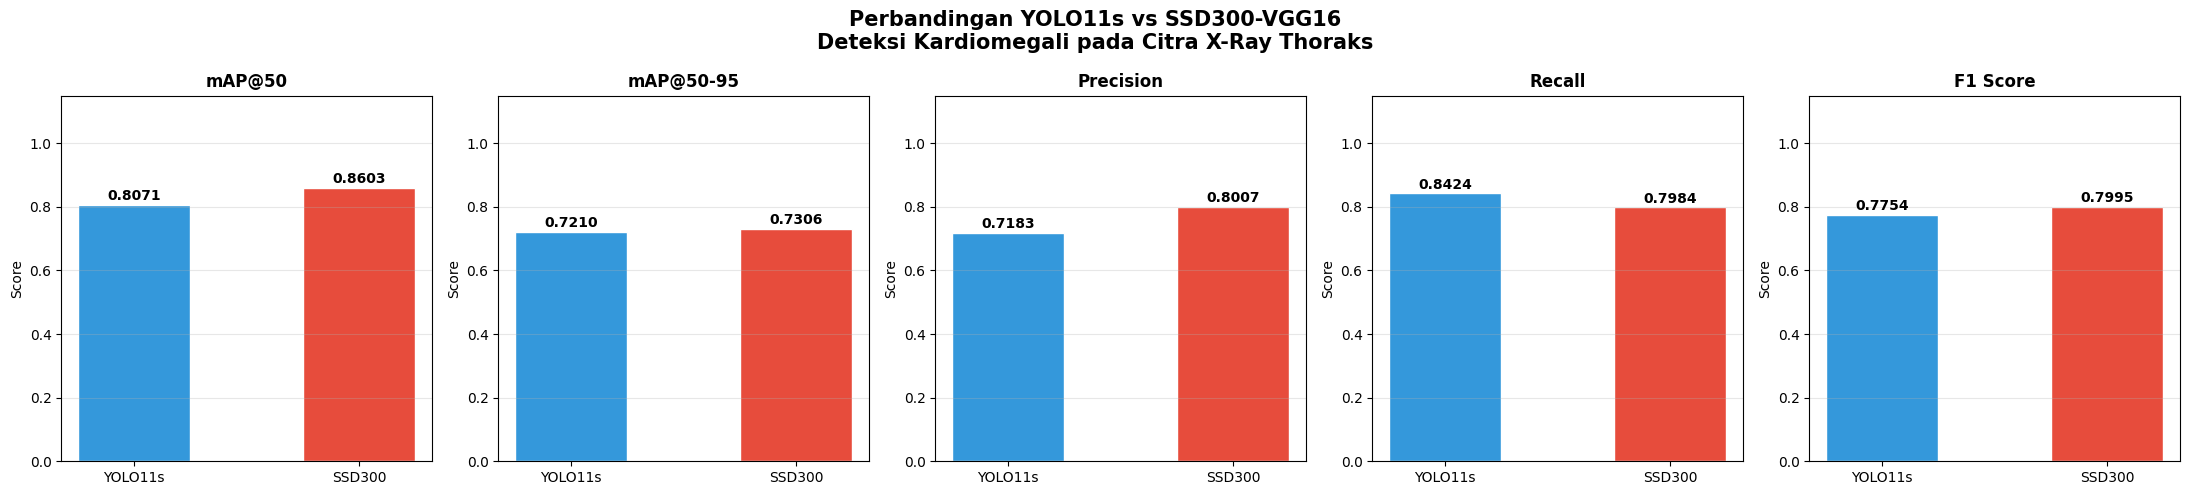

Chart saved: /kaggle/working/outputs/comparison_chart.png


In [22]:
comparison_df = pd.DataFrame({
    'Model': ['YOLO11s', 'SSD300-VGG16'],
    'mAP@50': [round(yolo_map50, 4), round(ssd_map50, 4)],
    'mAP@50-95': [round(yolo_map50_95, 4), round(ssd_map50_95, 4)],
    'Precision': [round(yolo_precision, 4), round(ssd_precision, 4)],
    'Recall': [round(yolo_recall, 4), round(ssd_recall, 4)],
    'F1 Score': [round(yolo_f1, 4), round(ssd_f1, 4)],
    'Inf (ms)': [round(yolo_infer_time, 2), round(ssd_infer_time, 2)],
})

print('\n' + '-'*70)
print('TABEL PERBANDINGAN AKHIR')
print('-'*70)
print(comparison_df.to_string(index=False))

csv_save_path = OUTPUT_DIR / 'comparison_results.csv'
comparison_df.to_csv(csv_save_path, index=False)
print(f'\nCSV saved: {csv_save_path}')

metric_cols = ['mAP@50', 'mAP@50-95', 'Precision', 'Recall', 'F1 Score']
fig, axes = plt.subplots(1, len(metric_cols), figsize=(22, 5))
fig.suptitle('Perbandingan YOLO11s vs SSD300-VGG16\nDeteksi Kardiomegali pada Citra X-Ray Thoraks', fontsize=15, fontweight='bold')
bar_colors = ['#3498DB', '#E74C3C']
model_labels = ['YOLO11s', 'SSD300']

for ax, col in zip(axes, metric_cols):
    vals = comparison_df[col].tolist()
    bars = ax.bar(model_labels, vals, color=bar_colors, edgecolor='white', width=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f'{val:.4f}',
                ha='center', va='bottom', fontweight='bold', fontsize=10)
    ax.set_title(col, fontsize=12, fontweight='bold'); ax.set_ylim(0, 1.15)
    ax.set_ylabel('Score'); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
chart_save_path = OUTPUT_DIR / 'comparison_chart.png'
plt.savefig(chart_save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Chart saved: {chart_save_path}')


## 11. Visualisasi Lokasi IoU pada Prediksi (Revisi Sidang #3)

Untuk setiap gambar sample:
- Kotak **merah** = Ground Truth (anotasi dokter).
- Kotak `#FF6B6B` = prediksi kelas **kardiomegali**, kotak `#4ECDC4` = prediksi kelas **normal** (berlaku untuk YOLO11 maupun SSD).
- Label menampilkan nama kelas + confidence score.
- Nilai **IoU (%)** antara box prediksi dan ground truth ditampilkan di judul/anotasi gambar.


In [28]:
def hex_to_bgr(hex_color):
    hex_color = hex_color.lstrip('#')
    r, g, b = tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))
    return (b, g, r)  # OpenCV pakai BGR

def compute_iou(boxA, boxB):
    xA, yA = max(boxA[0], boxB[0]), max(boxA[1], boxB[1])
    xB, yB = min(boxA[2], boxB[2]), min(boxA[3], boxB[3])
    inter = max(0, xB - xA) * max(0, yB - yA)
    areaA = max(0, boxA[2]-boxA[0]) * max(0, boxA[3]-boxA[1])
    areaB = max(0, boxB[2]-boxB[0]) * max(0, boxB[3]-boxB[1])
    union = areaA + areaB - inter
    return inter / union if union > 0 else 0.0

def draw_box_with_label(img, box, color_bgr, text, top=True):
    x1, y1, x2, y2 = [int(v) for v in box]
    cv2.rectangle(img, (x1, y1), (x2, y2), color_bgr, 3)
    font, scale, thick = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2
    (tw, th), _ = cv2.getTextSize(text, font, scale, thick)
    ty = y1 - 10 if top and y1 - th - 15 > 0 else y2 + th + 15
    box_y1, box_y2 = (ty - th - 8, ty + 4) if top and y1 - th - 15 > 0 else (ty - th - 4, ty + 8)
    cv2.rectangle(img, (x1, box_y1), (x1 + tw + 8, box_y2), color_bgr, -1)
    cv2.putText(img, text, (x1 + 4, ty), font, scale, (255, 255, 255), thick)
    return img

def load_yolo_gt_boxes(label_path, W, H):
    gt = []
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            p = line.strip().split()
            if len(p) == 5:
                cls_id = int(p[0])
                cx, cy, bw, bh = map(float, p[1:])
                x1, y1 = (cx-bw/2)*W, (cy-bh/2)*H
                x2, y2 = (cx+bw/2)*W, (cy+bh/2)*H
                gt.append({'class': cls_id, 'box': [x1, y1, x2, y2]})
    return gt

def visualize_iou(img_path, label_path, model_type='yolo', conf_thresh=0.4, save_name=None):
    """model_type: 'yolo' atau 'ssd'. Menggambar GT (merah) + prediksi (warna kelas) + IoU%."""
    orig = cv2.imread(str(img_path))
    orig = cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)
    H, W = orig.shape[:2]
    img = orig.copy()

    gt_boxes = load_yolo_gt_boxes(Path(label_path), W, H)

    preds = []  # list of {'class', 'box', 'conf'}
    if model_type == 'yolo':
        results = model_yolo11.predict(source=str(img_path), conf=conf_thresh, device=DEVICE, verbose=False)
        boxes_xyxy = results[0].boxes.xyxy.cpu().numpy()
        confs      = results[0].boxes.conf.cpu().numpy()
        clses      = results[0].boxes.cls.cpu().numpy().astype(int)
        for b, c, cl in zip(boxes_xyxy, confs, clses):
            preds.append({'class': int(cl), 'box': b.tolist(), 'conf': float(c)})
    else:
        transform_ssd = T.Compose([
            T.Resize((SSD_SIZE, SSD_SIZE)), T.ToTensor(),
            T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
        pil_img = Image.fromarray(orig)
        inp = transform_ssd(pil_img).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            out = ssd_model(inp)[0]
        keep = out['scores'] >= conf_thresh
        boxes_300 = out['boxes'][keep].cpu().numpy()
        confs     = out['scores'][keep].cpu().numpy()
        clses     = out['labels'][keep].cpu().numpy().astype(int) - 1  # 1,2 -> 0,1
        sx, sy = W / SSD_SIZE, H / SSD_SIZE
        for b, c, cl in zip(boxes_300, confs, clses):
            box_full = [b[0]*sx, b[1]*sy, b[2]*sx, b[3]*sy]
            preds.append({'class': int(cl), 'box': box_full, 'conf': float(c)})

    # gambar ground truth (MERAH)
    gt_color = hex_to_bgr(GT_COLOR_HEX)
    for gt in gt_boxes:
        img = draw_box_with_label(img, gt['box'], gt_color, f"GT: {CLASS_NAMES[gt['class']]}", top=True)

    # gambar prediksi + hitung IoU terhadap GT kelas yang sama
    iou_texts = []
    for pred in preds:
        color_hex = CLASS_COLORS[pred['class']]
        color_bgr = hex_to_bgr(color_hex)
        best_iou, best_gt = 0.0, None
        for gt in gt_boxes:
            if gt['class'] == pred['class']:
                iou = compute_iou(pred['box'], gt['box'])
                if iou > best_iou:
                    best_iou, best_gt = iou, gt
        label = f"{CLASS_NAMES[pred['class']]} {pred['conf']*100:.1f}%"
        img = draw_box_with_label(img, pred['box'], color_bgr, label, top=False)
        if best_gt is not None:
            iou_texts.append(f"IoU({CLASS_NAMES[pred['class']]})={best_iou*100:.1f}%")

    title = f"{model_type.upper()} — {Path(img_path).name}"
    if iou_texts:
        title += '  |  ' + ', '.join(iou_texts)

    plt.figure(figsize=(9, 9))
    plt.imshow(img)
    plt.title(title, fontsize=11, fontweight='bold')
    plt.axis('off')
    legend_handles = [
        patches.Patch(color=GT_COLOR_HEX, label='Ground Truth (dokter)'),
        patches.Patch(color=CLASS_COLORS[0], label=f'Prediksi: {CLASS_NAMES[0]}'),
        patches.Patch(color=CLASS_COLORS[1], label=f'Prediksi: {CLASS_NAMES[1]}'),
    ]
    plt.legend(handles=legend_handles, loc='upper right', fontsize=8, framealpha=0.9)
    plt.tight_layout()

    if save_name:
        out_path = OUTPUT_DIR / save_name
        plt.savefig(out_path, dpi=200, bbox_inches='tight')
        print(f'saved: {out_path}')
    plt.show()
    return preds, gt_boxes, iou_texts



Gambar: 006-07-03-1982_PNG.rf.43d16e60714e52d26055858d51bdf0de.jpg

--- YOLO11 ---
saved: /kaggle/working/outputs/iou_yolo11_006-07-03-1982_PNG.rf.43d16e60714e52d26055858d51bdf0de.png


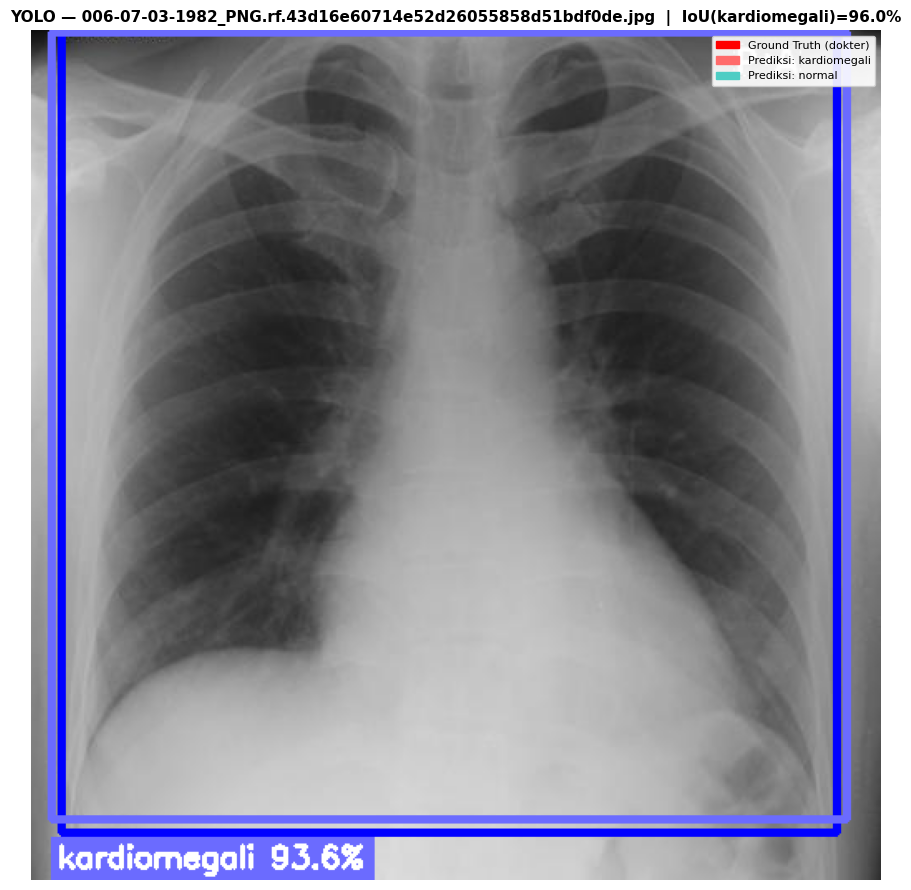


--- SSD300 ---
saved: /kaggle/working/outputs/iou_ssd300_006-07-03-1982_PNG.rf.43d16e60714e52d26055858d51bdf0de.png


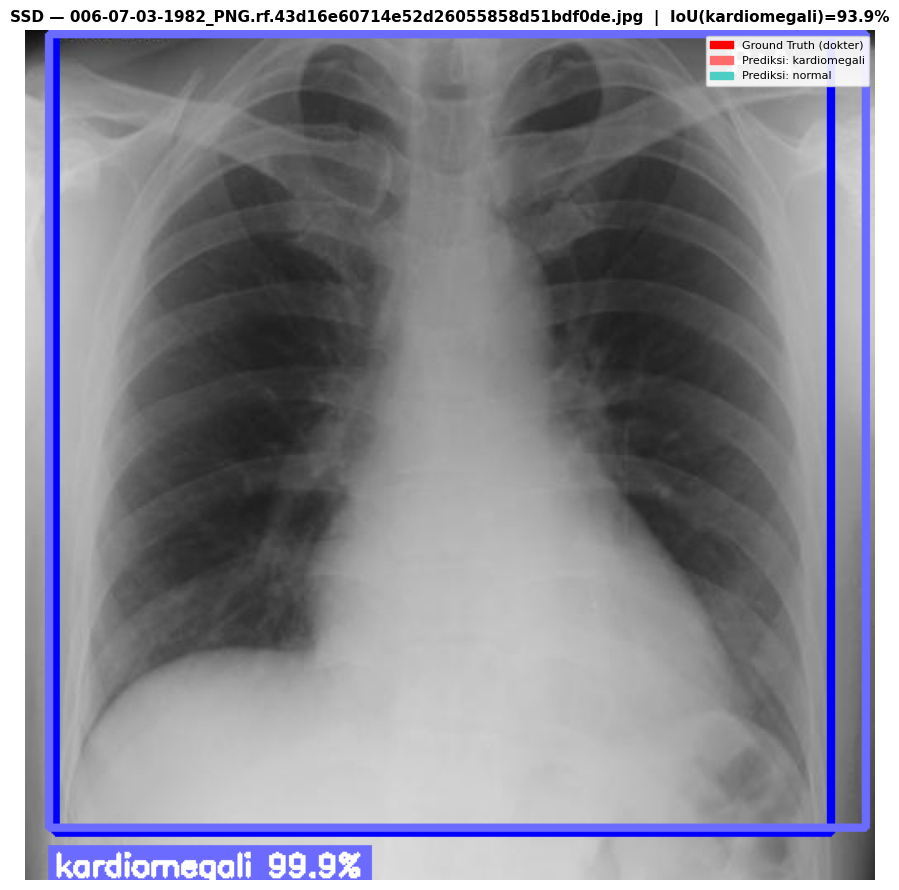


Gambar: 011-17-03-04-_PNG.rf.18163fb58df9c24a93c2256d93552368.jpg

--- YOLO11 ---
saved: /kaggle/working/outputs/iou_yolo11_011-17-03-04-_PNG.rf.18163fb58df9c24a93c2256d93552368.png


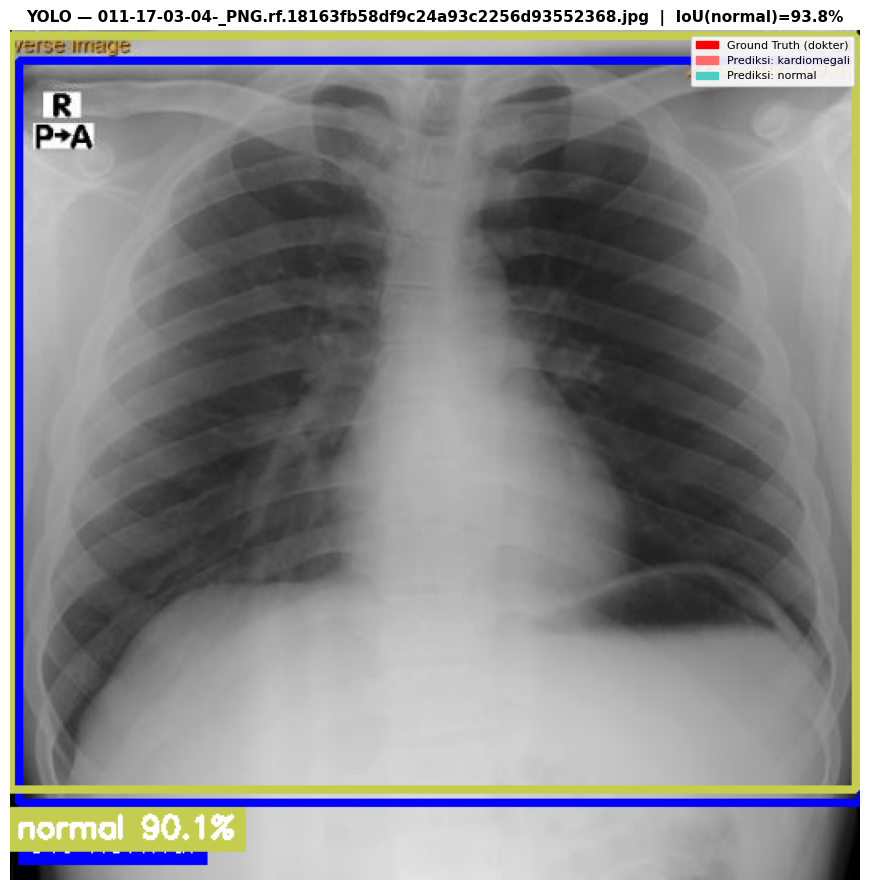


--- SSD300 ---
saved: /kaggle/working/outputs/iou_ssd300_011-17-03-04-_PNG.rf.18163fb58df9c24a93c2256d93552368.png


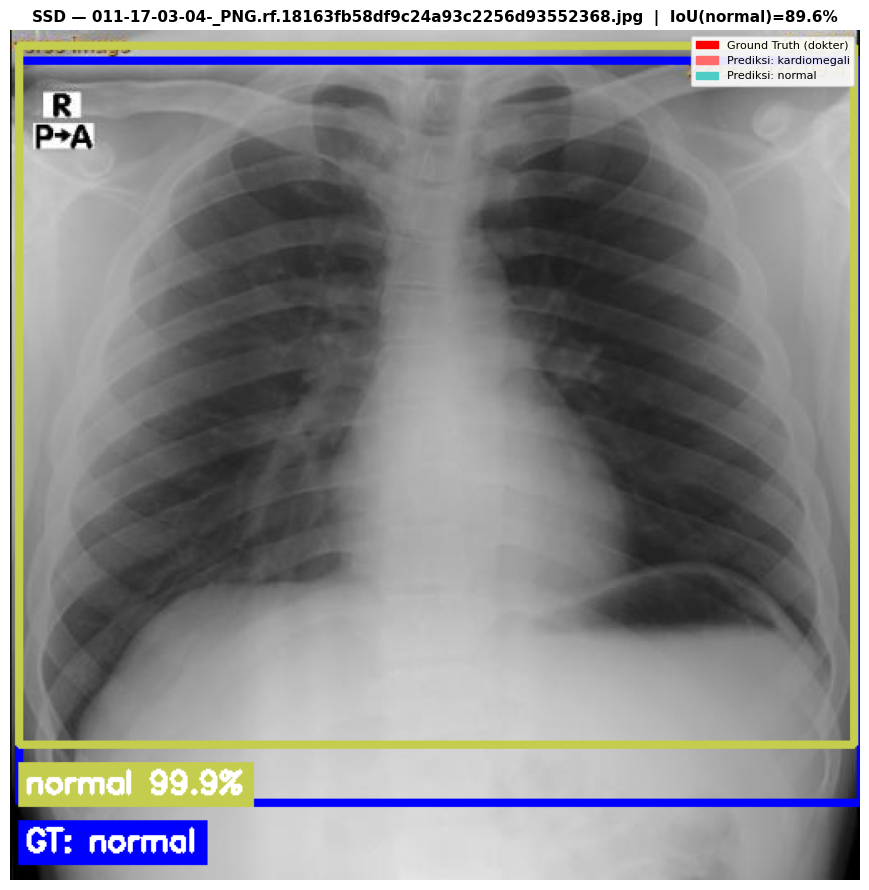


Gambar: 04-HARLY-SYAHFRIL-10-12-1984_PNG.rf.fb2f3520aedc767924e53ac833a26b6d.jpg

--- YOLO11 ---
saved: /kaggle/working/outputs/iou_yolo11_04-HARLY-SYAHFRIL-10-12-1984_PNG.rf.fb2f3520aedc767924e53ac833a26b6d.png


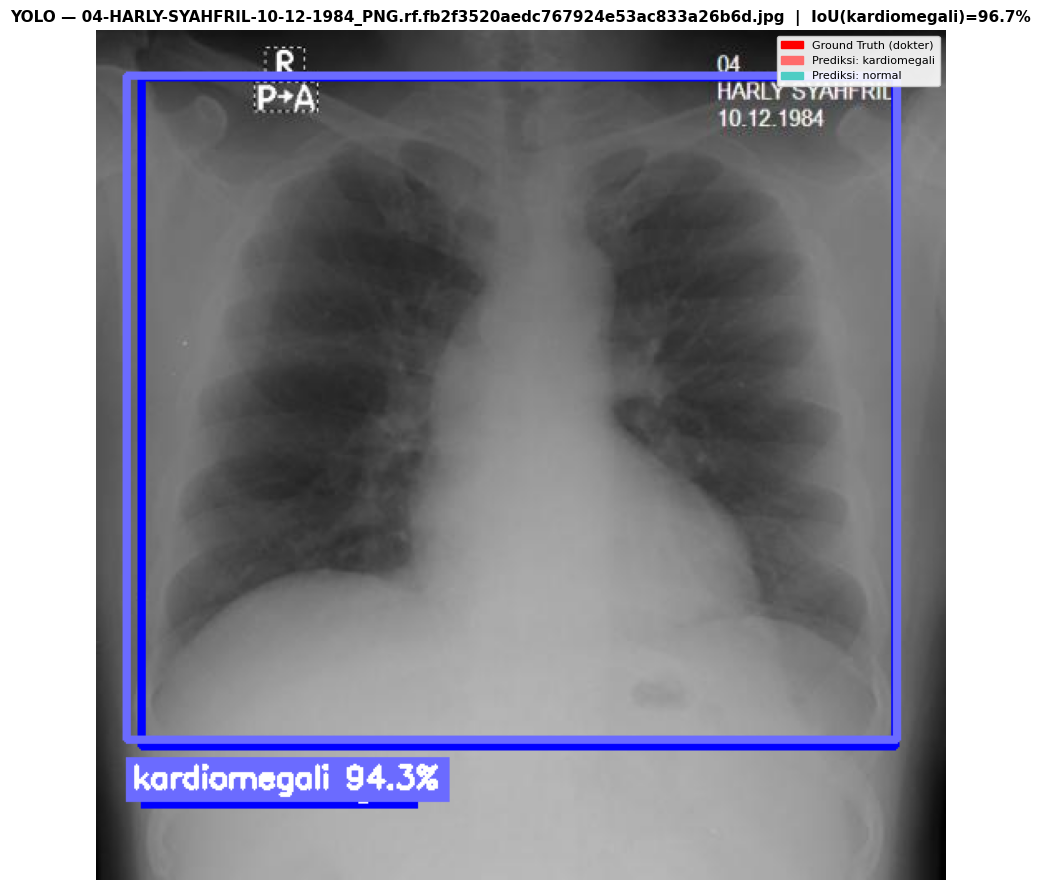


--- SSD300 ---
saved: /kaggle/working/outputs/iou_ssd300_04-HARLY-SYAHFRIL-10-12-1984_PNG.rf.fb2f3520aedc767924e53ac833a26b6d.png


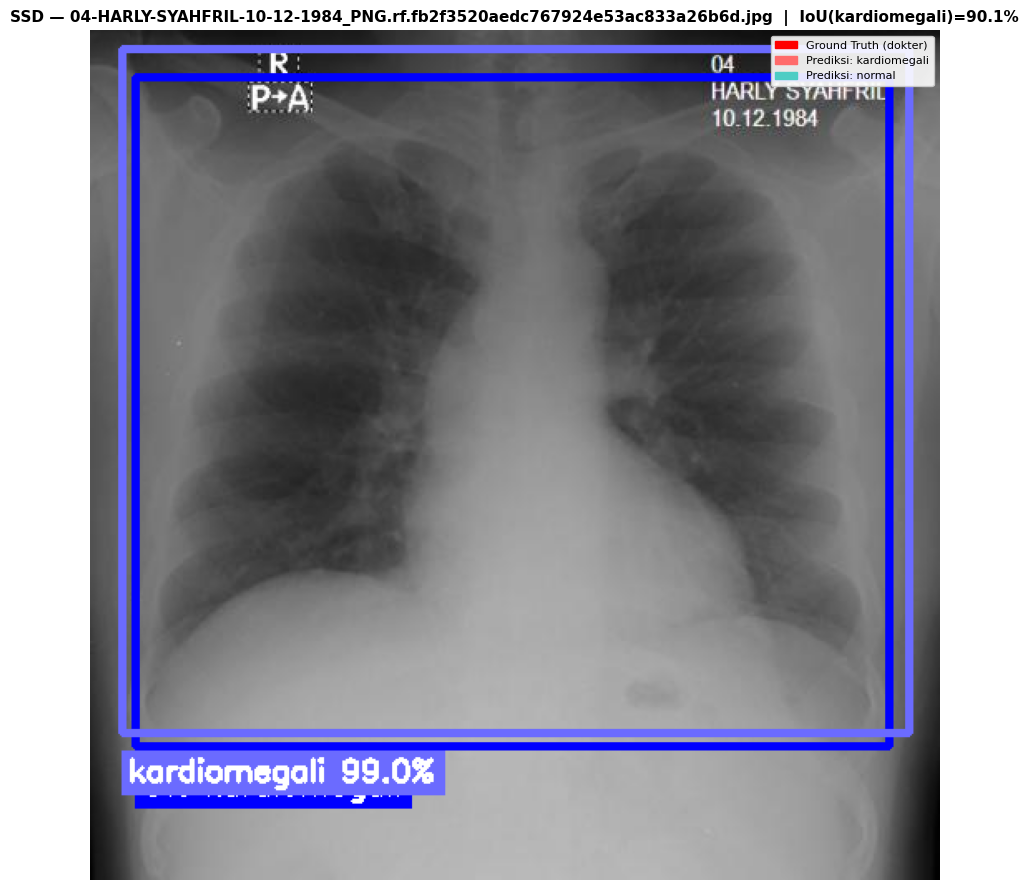


Gambar: 102-NONI-OKTARI-31-10-1995_jpg.rf.1adb7c73dcd3faf729ef96b719ddc895.jpg

--- YOLO11 ---
saved: /kaggle/working/outputs/iou_yolo11_102-NONI-OKTARI-31-10-1995_jpg.rf.1adb7c73dcd3faf729ef96b719ddc895.png


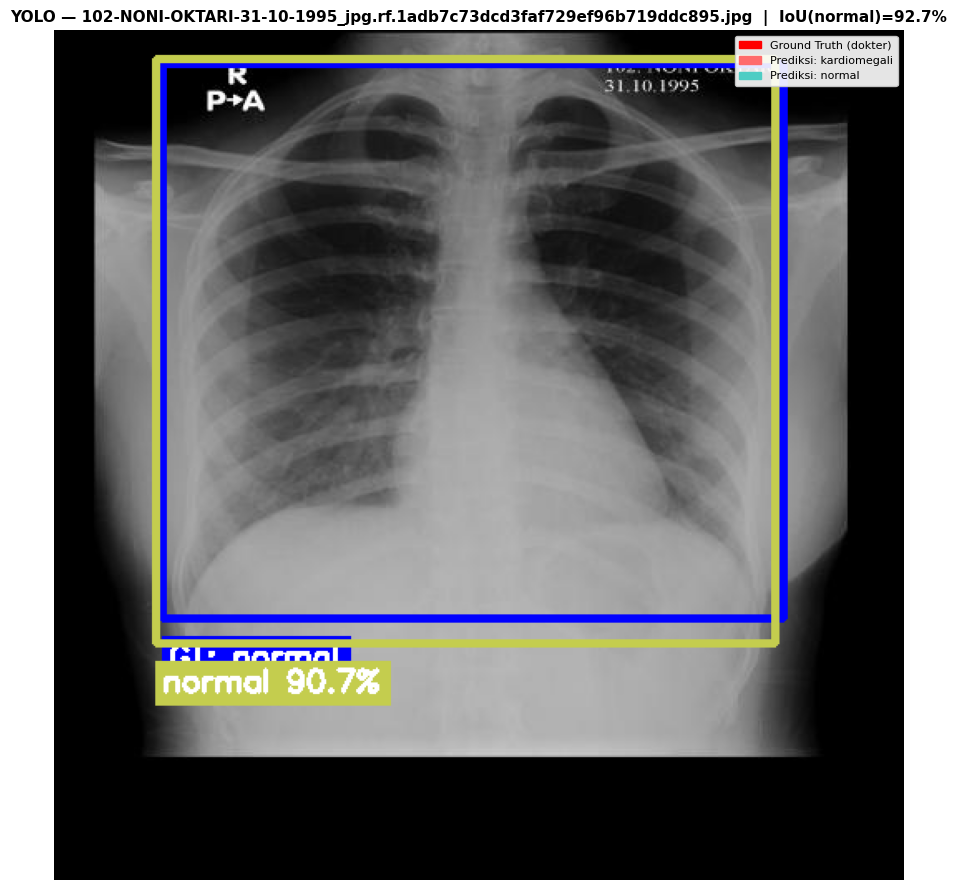


--- SSD300 ---
saved: /kaggle/working/outputs/iou_ssd300_102-NONI-OKTARI-31-10-1995_jpg.rf.1adb7c73dcd3faf729ef96b719ddc895.png


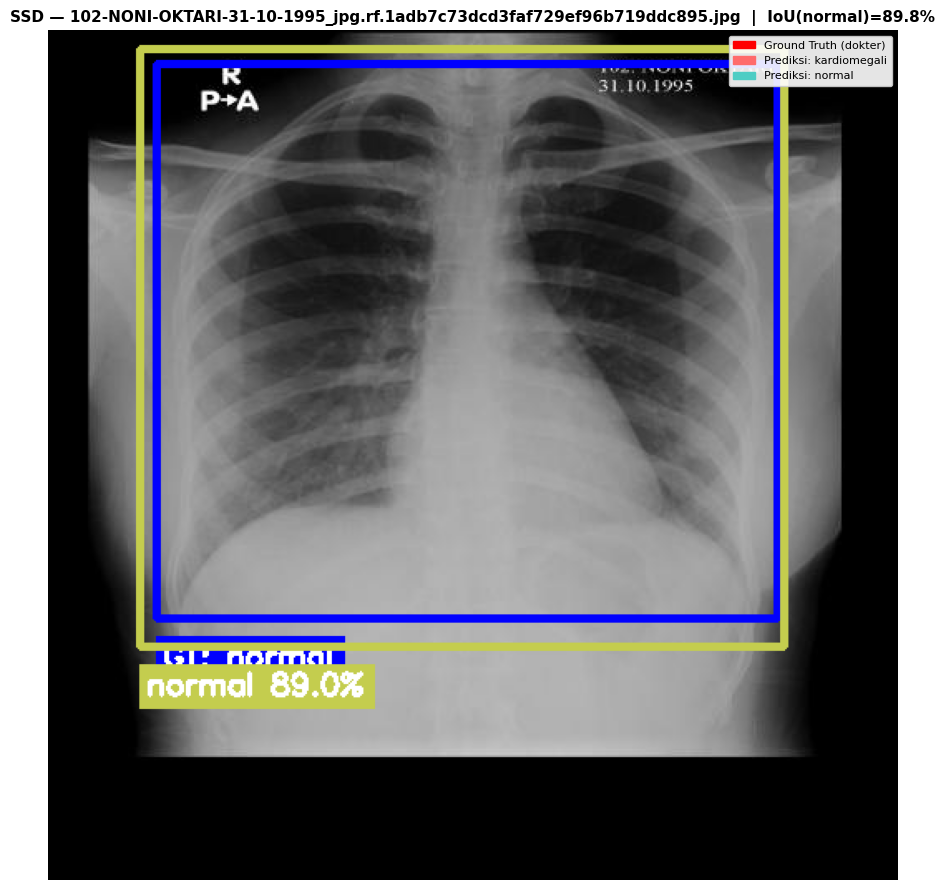

In [29]:
# Sample IoU visualization pada beberapa gambar test — YOLO11 vs SSD300
sample_files = sorted(list(TEST_IMG.glob('*.*')))[:4]

model_yolo11 = YOLO(str(YOLO_BEST))
ssd_model.load_state_dict(torch.load(SSD_CKPT, map_location=DEVICE, weights_only=True))
ssd_model.eval().to(DEVICE)

for img_path in sample_files:
    lbl_path = TEST_LBL / f'{img_path.stem}.txt'
    print('\n' + '='*80)
    print(f'Gambar: {img_path.name}')
    print('='*80)

    print('\n--- YOLO11 ---')
    visualize_iou(img_path, lbl_path, model_type='yolo',
                  save_name=f'iou_yolo11_{img_path.stem}.png')

    print('\n--- SSD300 ---')
    visualize_iou(img_path, lbl_path, model_type='ssd',
                  save_name=f'iou_ssd300_{img_path.stem}.png')


## 12. Inferensi Satu Gambar (opsional)

Ganti `CUSTOM_IMAGE_PATH` dengan path gambar X-ray lain (mis. hasil upload ke `/kaggle/working/`) untuk melihat prediksi + IoU pada gambar tunggal.


In [ ]:
CUSTOM_IMAGE_PATH = None  # contoh: '/kaggle/working/contoh.png'

if CUSTOM_IMAGE_PATH is not None and Path(CUSTOM_IMAGE_PATH).exists():
    dummy_label = Path('/kaggle/working/empty.txt')
    dummy_label.write_text('')  # tanpa ground truth untuk gambar eksternal
    print('--- YOLO11 ---')
    visualize_iou(CUSTOM_IMAGE_PATH, dummy_label, model_type='yolo')
    print('--- SSD300 ---')
    visualize_iou(CUSTOM_IMAGE_PATH, dummy_label, model_type='ssd')
else:
    print('Set CUSTOM_IMAGE_PATH untuk menjalankan inferensi pada gambar custom.')


## 13. Ringkasan Output

Semua artefak (model, kurva training, confusion matrix valid & test, tabel hyperparameter, tabel & grafik perbandingan akhir, visualisasi IoU) tersimpan di `/kaggle/working/outputs/` dan bisa diunduh dari panel **Output** Kaggle Notebook setelah run selesai.


In [ ]:
print('Isi folder outputs:')
for f in sorted(OUTPUT_DIR.rglob('*')):
    if f.is_file():
        print(' -', f.relative_to(OUTPUT_DIR))
